# YZ50 Hafta 11-12: GPT-2'yi hızlandırmak, gerçek veride eğitmek ve ölçmek

Hafta 10'da kendi yazdığım GPT-2'ye OpenAI'ın ağırlıklarını yükleyip konuşturmuştum. Bu notebook'ta iki haftanın görevlerini birlikte yapıyorum. İlk yarıda (Hafta 11) modeli hızlı eğitilebilir hâle getiriyorum: data loader, weight tying, başlangıç değerleri, hızlandırma adımları ve GPT-3'ün eğitim ayarları. İkinci yarıda (Hafta 12) FineWeb-Edu'dan hazırladığım veride modeli bir saat eğitiyorum ve HellaSwag'de OpenAI'ın GPT-2'siyle karşılaştırıyorum. Kaynak: Karpathy, *Let's reproduce GPT-2 (124M)*, videonun 1:02:00 – 2:46:52 ve 3:10:21 – 3:56:21 aralıkları.

Colab yerine kendi bilgisayarımda çalıştırdım: **NVIDIA GeForce RTX 4060 Laptop GPU (8 GB)**, Windows 11.

| Bölüm | İçerik | Videoda |
|---|---|---|
| Hafta 11 / Görev 1 | Data loader, weight tying, başlangıç değerleri | 1:02:00 – 1:22:18 |
| Hafta 11 / Görev 2 | Hızlandırma: TF32, bfloat16, torch.compile, flash attention, vocab 50.304 | 1:22:18 – 2:14:55 |
| Hafta 11 / Görev 3 | AdamW, gradient clipping, cosine LR, weight decay, gradient accumulation | 2:14:55 – 2:46:52 |
| Hafta 11 / Görev 4 (ek, b) | Türkçe metin: GPT-2 tokenizer'ı ile Hafta 9 tokenizer'ı | – |
| Hafta 12 / Görev 1 | FineWeb-Edu'yu token'la, shard'lara böl | 3:10:21 – 3:23:10 |
| Hafta 12 / Görev 2 | Doğrulama loss'u ve örnek üretme | 3:23:10 – 3:28:23 |
| Hafta 12 / Görev 3 | Bir saatlik eğitim | 3:28:23 – 3:43:05 |
| Hafta 12 / Görev 4 | HellaSwag: kendi modelim ve OpenAI GPT-2 | 3:28:23 – 3:56:21 |
| Hafta 12 / Görev 5 (ek) | Türkçe GPT-2 | – |

## Kurulum ve ayarlar

Bilgisayarımdaki PyTorch ilk başta CPU sürümüydü, CUDA'lı sürümü (`torch 2.13.0+cu130`) kurdum. Windows'ta `torch.compile` için Triton gerekiyor, onun Windows sürümü `triton-windows` paketi. Paketin içinde küçük bir C derleyicisi (TinyCC) geliyor ama Microsoft Store'dan kurulan Python'da Triton bu derleyicinin yolunu bulamıyor, bu yüzden `CC` değişkeniyle yolu kendim gösteriyorum.

In [1]:
import sys

%pip install -q tiktoken datasets transformers matplotlib pandas numpy regex
if sys.platform == "win32":
    %pip install -q "triton-windows<3.10"

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: C:\Users\mehme\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 26.1.2 -> 26.3
[notice] To update, run: C:\Users\mehme\AppData\Local\Microsoft\WindowsApps\PythonSoftwareFoundation.Python.3.13_qbz5n2kfra8p0\python.exe -m pip install --upgrade pip


In [2]:
import warnings

warnings.filterwarnings("ignore")

import gc
import importlib.util
import json
import logging
import math
import os
import re
import time
import unicodedata
from collections import Counter
from dataclasses import dataclass

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import regex
import torch
import torch.nn as nn
import torch.nn.functional as F
import tiktoken
from datasets import load_dataset
from IPython.display import display
from torch.nn.attention import SDPBackend, sdpa_kernel
from transformers import GPT2LMHeadModel

logging.getLogger("torch._inductor").setLevel(logging.ERROR)
if sys.platform == "win32" and importlib.util.find_spec("triton") is not None:
    os.environ["CC"] = os.path.join(os.path.dirname(importlib.util.find_spec("triton").origin), "runtime", "tcc", "tcc.exe")

SEED = 1337
SHAKESPEARE_YOLU = "../hafta7/input.txt"
ROMAN_YOLU = "../kurk_mantolu_madonna.txt"
VERI_EDU = "veri_fineweb_edu"
VERI_TR = "veri_fineweb2_tr"

H11_B, H11_T = 4, 512
HIZ_ISINMA, HIZ_ADIM = 5, 15
H11_TOPLAM_BATCH = 2**15
H11_ADIM = 50
H11_WARMUP = 10

TR_VOCAB = 512
TR_SURE = 90
TR_LR = 3e-4
TR_DEGER_HER = 20

SHARD_TOKEN = 10_000_000
EDU_SHARD = 10
TR_SHARD = 4
B, T = 4, 1024
TOPLAM_BATCH = 2**16
MAX_LR = 6e-4
MIN_LR = MAX_LR * 0.1
WEIGHT_DECAY = 0.1
EGITIM_DAKIKA = 60
TR_EGITIM_DAKIKA = 15
DEGER_HER = 100
HS_HER = 250
ORNEK_HER = 250
TR_DEGER_HER_H12 = 50
TR_ORNEK_HER = 100
VAL_ADIM = 20
HS_ARA_ORNEK = 1000
HS_SON_ORNEK = 10042
ORNEK_ADET = 4
ORNEK_UZUNLUK = 32
TOP_K = 50

device = "cuda" if torch.cuda.is_available() else "cpu"
device_type = "cuda" if device.startswith("cuda") else "cpu"
torch.manual_seed(SEED)
if device == "cuda":
    torch.cuda.manual_seed(SEED)

enc = tiktoken.get_encoding("gpt2")
EOT = enc._special_tokens["<|endoftext|>"]
derleme_var = device == "cuda" and importlib.util.find_spec("triton") is not None


def nokta(n):
    return f"{n:,}".replace(",", ".")


print(f"PyTorch {torch.__version__}  |  cihaz: {device}" + (f" ({torch.cuda.get_device_name(0)})" if device == "cuda" else ""))
if device == "cuda":
    print(f"GPU belleği: {torch.cuda.get_device_properties(0).total_memory / 2**30:.1f} GB  |  compute capability: {torch.cuda.get_device_capability()}  |  bfloat16: {torch.cuda.is_bf16_supported()}")
print(f"torch.compile için Triton: {'var' if derleme_var else 'yok'}")
print(f"GPT-2 tokenizer vocab boyutu: {enc.n_vocab}  |  <|endoftext|> id: {EOT}")

PyTorch 2.13.0+cu130  |  cihaz: cuda (NVIDIA GeForce RTX 4060 Laptop GPU)
GPU belleği: 8.0 GB  |  compute capability: (8, 9)  |  bfloat16: True
torch.compile için Triton: var
GPT-2 tokenizer vocab boyutu: 50257  |  <|endoftext|> id: 50256


# Hafta 11: GPT-2'yi hızlı eğitilebilir hâle getirmek

## Görev 1: Data loader, weight tying ve başlangıç değerleri *(Video 1:02:00 – 1:22:18)*

Metni batch'lere bölen küçük bir data loader yaz ve metnin tamamında eğit. Weight tying'i ekle, kaç parametre kazandırdığını hesapla. Başlangıç değerlerini videodaki gibi ayarla: std 0.02, residual katmanlarda 1/√(2·n_layer) ile ölçekleme. Neden ölçeklediğimizi kendi cümlelerinle yaz.

Model Hafta 10'daki GPT-2 ile aynı, üstüne bu iki haftada gereken şeyleri ekledim. Hepsini `GPTConfig` içinde açıp kapatılabilir yaptım, çünkü Görev 1 ve 2'de her değişikliği tek tek ölçeceğim:

- `agirlik_paylas`: `lm_head` ile `wte` aynı tensör (weight tying).
- `ozel_baslangic` ve `artik_olcekle`: videodaki başlangıç değerleri. `c_proj` katmanlarına `NANOGPT_SCALE_INIT` işareti koyuyorum, bunlar residual akışa ekleme yapan katmanlar.
- `flash`: attention'ı `F.scaled_dot_product_attention` ile hesaplamak (Görev 2).
- `configure_optimizers`: weight decay'i yalnız 2 boyutlu parametrelere uygulayan AdamW (Görev 3).

In [3]:
@dataclass
class GPTConfig:
    block_size: int = 1024
    vocab_size: int = 50257
    n_layer: int = 12
    n_head: int = 12
    n_embd: int = 768
    agirlik_paylas: bool = True
    ozel_baslangic: bool = True
    artik_olcekle: bool = True
    flash: bool = False


class CausalSelfAttention(nn.Module):
    def __init__(self, config):
        super().__init__()
        assert config.n_embd % config.n_head == 0
        self.c_attn = nn.Linear(config.n_embd, 3 * config.n_embd)
        self.c_proj = nn.Linear(config.n_embd, config.n_embd)
        self.c_proj.NANOGPT_SCALE_INIT = 1
        self.n_head = config.n_head
        self.n_embd = config.n_embd
        self.flash = config.flash
        maske = torch.tril(torch.ones(config.block_size, config.block_size))
        self.register_buffer("maske", maske.view(1, 1, config.block_size, config.block_size), persistent=False)

    def forward(self, x):
        B, T, C = x.size()
        q, k, v = self.c_attn(x).split(self.n_embd, dim=2)
        q = q.view(B, T, self.n_head, C // self.n_head).transpose(1, 2)
        k = k.view(B, T, self.n_head, C // self.n_head).transpose(1, 2)
        v = v.view(B, T, self.n_head, C // self.n_head).transpose(1, 2)
        if self.flash:
            y = F.scaled_dot_product_attention(q, k, v, is_causal=True)
        else:
            att = (q @ k.transpose(-2, -1)) * (k.size(-1) ** -0.5)
            att = att.masked_fill(self.maske[:, :, :T, :T] == 0, float("-inf"))
            att = F.softmax(att, dim=-1)
            y = att @ v
        y = y.transpose(1, 2).contiguous().view(B, T, C)
        return self.c_proj(y)


class MLP(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.c_fc = nn.Linear(config.n_embd, 4 * config.n_embd)
        self.gelu = nn.GELU(approximate="tanh")
        self.c_proj = nn.Linear(4 * config.n_embd, config.n_embd)
        self.c_proj.NANOGPT_SCALE_INIT = 1

    def forward(self, x):
        return self.c_proj(self.gelu(self.c_fc(x)))


class Block(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.ln_1 = nn.LayerNorm(config.n_embd)
        self.attn = CausalSelfAttention(config)
        self.ln_2 = nn.LayerNorm(config.n_embd)
        self.mlp = MLP(config)

    def forward(self, x):
        x = x + self.attn(self.ln_1(x))
        x = x + self.mlp(self.ln_2(x))
        return x


class GPT(nn.Module):
    def __init__(self, config):
        super().__init__()
        self.config = config
        self.transformer = nn.ModuleDict(dict(
            wte=nn.Embedding(config.vocab_size, config.n_embd),
            wpe=nn.Embedding(config.block_size, config.n_embd),
            h=nn.ModuleList([Block(config) for _ in range(config.n_layer)]),
            ln_f=nn.LayerNorm(config.n_embd),
        ))
        self.lm_head = nn.Linear(config.n_embd, config.vocab_size, bias=False)
        if config.agirlik_paylas:
            self.transformer.wte.weight = self.lm_head.weight
        if config.ozel_baslangic:
            self.apply(self._init_weights)

    def _init_weights(self, module):
        if isinstance(module, nn.Linear):
            std = 0.02
            if hasattr(module, "NANOGPT_SCALE_INIT") and self.config.artik_olcekle:
                std *= (2 * self.config.n_layer) ** -0.5
            torch.nn.init.normal_(module.weight, mean=0.0, std=std)
            if module.bias is not None:
                torch.nn.init.zeros_(module.bias)
        elif isinstance(module, nn.Embedding):
            torch.nn.init.normal_(module.weight, mean=0.0, std=0.02)

    def forward(self, idx, targets=None):
        B, T = idx.size()
        assert T <= self.config.block_size, f"Dizi uzunluğu {T}, block_size {self.config.block_size} değerini aşıyor"
        pos = torch.arange(0, T, dtype=torch.long, device=idx.device)
        x = self.transformer.wte(idx) + self.transformer.wpe(pos)
        for blok in self.transformer.h:
            x = blok(x)
        x = self.transformer.ln_f(x)
        logits = self.lm_head(x)
        loss = None
        if targets is not None:
            loss = F.cross_entropy(logits.view(-1, logits.size(-1)), targets.view(-1))
        return logits, loss

    def configure_optimizers(self, weight_decay, learning_rate, device_type, yazdir=False):
        parametreler = {ad: p for ad, p in self.named_parameters() if p.requires_grad}
        decay = [p for p in parametreler.values() if p.dim() >= 2]
        nodecay = [p for p in parametreler.values() if p.dim() < 2]
        gruplar = [
            {"params": decay, "weight_decay": weight_decay},
            {"params": nodecay, "weight_decay": 0.0},
        ]
        fused = device_type == "cuda"
        if yazdir:
            print(f"weight decay uygulanan   : {len(decay):3d} tensör, {nokta(sum(p.numel() for p in decay))} parametre")
            print(f"weight decay uygulanmayan: {len(nodecay):3d} tensör, {nokta(sum(p.numel() for p in nodecay))} parametre")
            print(f"fused AdamW: {fused}")
        return torch.optim.AdamW(gruplar, lr=learning_rate, betas=(0.9, 0.95), eps=1e-8, fused=fused)

### Data loader

Hafta 10'da tek bir batch'i ezberletmiştim. Şimdi bütün metni sırayla dolaşan bir loader yazıyorum. Metni bir kez token'lıyor, her çağrıda sıradaki B×T + 1 token'ı alıp `x` ve bir sağa kaymış `y` hâline getiriyor. Bir sonraki batch'e yer kalmayınca başa dönüyor ve tur sayısını artırıyor. Veri olarak yine Tiny Shakespeare.

In [4]:
class DataLoaderLite:
    def __init__(self, tokenler, B, T):
        self.tokenler = torch.tensor(tokenler, dtype=torch.long)
        self.B, self.T = B, T
        self.konum = 0
        self.tur = 0

    def next_batch(self):
        B, T = self.B, self.T
        tampon = self.tokenler[self.konum : self.konum + B * T + 1]
        x = tampon[:-1].view(B, T)
        y = tampon[1:].view(B, T)
        self.konum += B * T
        if self.konum + B * T + 1 > len(self.tokenler):
            self.konum = 0
            self.tur += 1
        return x, y


with open(SHAKESPEARE_YOLU, encoding="utf-8") as f:
    sh_metin = f.read()
sh_tokenler = enc.encode(sh_metin)
tur_basina_batch = (len(sh_tokenler) - 1) // (H11_B * H11_T)

loader = DataLoaderLite(sh_tokenler, H11_B, H11_T)
x, y = loader.next_batch()
assert bool((x.view(-1)[1:] == y.view(-1)[:-1]).all())
print(f"Metin: {nokta(len(sh_metin))} karakter -> {nokta(len(sh_tokenler))} token")
print(f"Bir batch: {H11_B} x {H11_T} = {nokta(H11_B * H11_T)} token  |  metnin tamamı {tur_basina_batch} batch")
print(f"x: {tuple(x.shape)}  y: {tuple(y.shape)}")
print(f"\nx[1] ilk 60 karakter: {enc.decode(x[1].tolist())[:60]!r}")

Metin: 1.115.394 karakter -> 338.025 token
Bir batch: 4 x 512 = 2.048 token  |  metnin tamamı 165 batch
x: (4, 512)  y: (4, 512)

x[1] ilk 60 karakter: ', to tire in repetition.\nWhat shouts are these? The other si'


### Weight tying

GPT-2'de giriş embedding'i (`wte`, token → vektör) ve çıkış katmanı (`lm_head`, vektör → token skorları) aynı matrisi kullanıyor. İkisi de 50.257 × 768. Fikir şu: anlamca birbirine yakın iki token girişte yakın vektörler almalı, çıkışta da benzer olasılıklar almalı. Aynı matrisi iki yerde kullanınca bu kendiliğinden oluyor. Bir de parametre kazancı var: ayrı tutarsak `wte` kadar parametreyi iki kez ödüyoruz.

In [5]:
paylasimsiz = GPT(GPTConfig(agirlik_paylas=False))
paylasimli = GPT(GPTConfig())
p_ayri = sum(p.numel() for p in paylasimsiz.parameters())
p_ortak = sum(p.numel() for p in paylasimli.parameters())
wte_boyut = paylasimli.transformer.wte.weight.numel()

display(pd.DataFrame([
    ("lm_head ve wte ayrı", nokta(p_ayri)),
    ("lm_head ve wte ortak (weight tying)", nokta(p_ortak)),
    ("Kazanç", nokta(p_ayri - p_ortak)),
    ("wte'nin boyutu (50257 x 768)", nokta(wte_boyut)),
    ("Kazancın ayrı modele oranı", f"%{(p_ayri - p_ortak) / p_ayri * 100:.1f}"),
], columns=["Model", "Parametre"]).style.hide(axis="index"))

print(f"lm_head.weight ile wte.weight aynı nesne mi: {paylasimli.lm_head.weight is paylasimli.transformer.wte.weight}")
print(f"Bellekte aynı adres mi: {paylasimli.lm_head.weight.data_ptr() == paylasimli.transformer.wte.weight.data_ptr()}")
del paylasimsiz, paylasimli

Model,Parametre
lm_head ve wte ayrı,163.037.184
lm_head ve wte ortak (weight tying),124.439.808
Kazanç,38.597.376
wte'nin boyutu (50257 x 768),38.597.376
Kazancın ayrı modele oranı,%23.7


lm_head.weight ile wte.weight aynı nesne mi: True
Bellekte aynı adres mi: True


**Cevap: Weight tying kaç parametre kazandırdı?**

**38.597.376** parametre, yani `wte`'nin kendisi kadar (50.257 × 768). Model 163.037.184'ten 124.439.808'e indi. Ayrı modelin %23.7'si sadece çıkış katmanıymış. Hafta 10'da kendi modelim tam bu yüzden 163M çıkmıştı. İki isim de bellekte aynı adresi gösteriyor, yani ortada tek bir tensör var ve iki yerden de gradient alıyor.

### Başlangıç değerleri

Videodaki ayar: bütün `Linear` ve `Embedding` ağırlıkları ortalaması 0, std'si 0.02 olan normal dağılımdan, bias'lar 0. Residual akışa ekleme yapan iki katmanın (`attn.c_proj` ve `mlp.c_proj`) std'si ayrıca 1/√(2·n_layer) ile çarpılıyor. 2 çarpanı, her blokta residual akışa iki ekleme yapıldığı için var (biri attention, biri MLP), 12 blokta toplam 24 ekleme.

Ölçeklemenin ne işe yaradığını görmek için önce videodaki küçük deneyi yaptım: sıfırdan başlayan bir vektöre 100 kez rastgele bir vektör ekliyorum. Sonra aynı şeyi gerçek modelde ölçtüm: başlangıçta, her bloktan sonra residual akışın std'si ne oluyor? Farkı daha net görmek için 12 bloğun yanında 48 bloklu bir modele de baktım.

100 eklemeden sonra std, ölçeksiz : 9.923  (beklenen √100 = 10.0)
100 eklemeden sonra std, 1/√100 ile: 0.999  (beklenen 1)


n_layer,Başlangıç,Embedding std,Son blok std,Büyüme (kat),İlk loss
12,PyTorch varsayılanı,0.9994,1.2455,1.25,10.9860
12,"std 0.02, ölçeksiz",0.0283,1.5251,53.96,10.9190
12,"std 0.02, 1/√(2·n_layer) ile",0.0283,0.2912,10.30,10.9477
48,PyTorch varsayılanı,0.9994,2.0444,2.05,10.9391
48,"std 0.02, ölçeksiz",0.0283,3.1363,110.76,10.9290
48,"std 0.02, 1/√(2·n_layer) ile",0.0283,0.3062,10.81,10.8688


ln(50257) = 10.8249


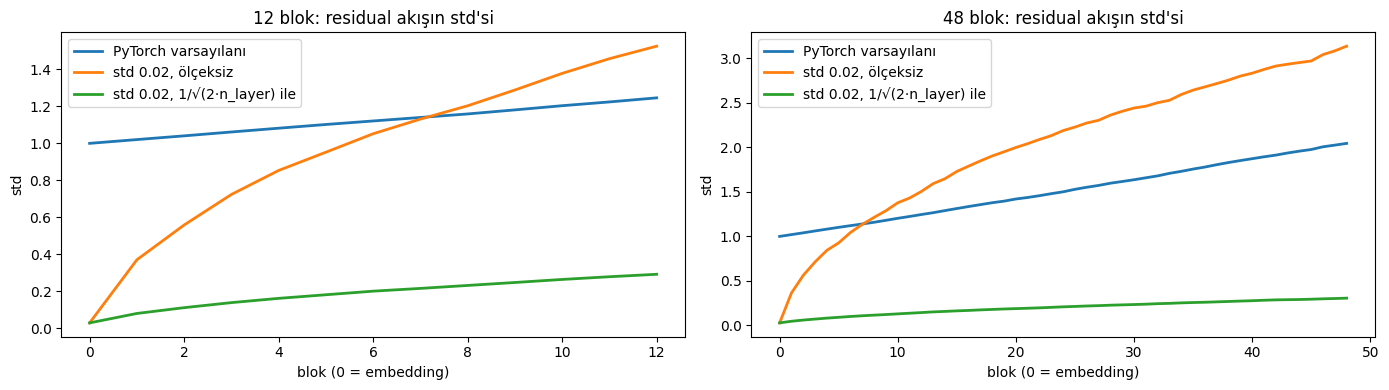

In [6]:
torch.manual_seed(SEED)
n = 100
x_olceksiz = torch.zeros(768)
x_olcekli = torch.zeros(768)
for _ in range(n):
    x_olceksiz += torch.randn(768)
    x_olcekli += n**-0.5 * torch.randn(768)
print(f"{n} eklemeden sonra std, ölçeksiz : {x_olceksiz.std().item():.3f}  (beklenen √{n} = {n**0.5:.1f})")
print(f"{n} eklemeden sonra std, 1/√{n} ile: {x_olcekli.std().item():.3f}  (beklenen 1)")


@torch.no_grad()
def artik_std(model, x):
    B, T = x.size()
    pos = torch.arange(T, device=x.device)
    h = model.transformer.wte(x) + model.transformer.wpe(pos)
    stdler = [h.std().item()]
    for blok in model.transformer.h:
        h = blok(h)
        stdler.append(h.std().item())
    return stdler


x, y = DataLoaderLite(sh_tokenler, H11_B, H11_T).next_batch()
x, y = x.to(device), y.to(device)
ayarlar = {
    "PyTorch varsayılanı": dict(ozel_baslangic=False),
    "std 0.02, ölçeksiz": dict(artik_olcekle=False),
    "std 0.02, 1/√(2·n_layer) ile": dict(),
}
egriler, satirlar = {}, []
for n_layer in (12, 48):
    for ad, ayar in ayarlar.items():
        torch.manual_seed(SEED)
        m = GPT(GPTConfig(n_layer=n_layer, **ayar)).to(device)
        stdler = artik_std(m, x)
        with torch.no_grad():
            _, loss = m(x, y)
        egriler[(n_layer, ad)] = stdler
        satirlar.append((n_layer, ad, f"{stdler[0]:.4f}", f"{stdler[-1]:.4f}", f"{stdler[-1] / stdler[0]:.2f}", f"{loss.item():.4f}"))
        del m
torch.cuda.empty_cache()

display(pd.DataFrame(satirlar, columns=["n_layer", "Başlangıç", "Embedding std", "Son blok std", "Büyüme (kat)", "İlk loss"]).style.hide(axis="index"))
print(f"ln(50257) = {math.log(50257):.4f}")

fig, eksenler = plt.subplots(1, 2, figsize=(14, 4))
for eksen, n_layer in zip(eksenler, (12, 48)):
    for ad in ayarlar:
        eksen.plot(egriler[(n_layer, ad)], label=ad, linewidth=2)
    eksen.set_title(f"{n_layer} blok: residual akışın std'si")
    eksen.set_xlabel("blok (0 = embedding)")
    eksen.set_ylabel("std")
    eksen.legend()
plt.tight_layout()
plt.show()

**Cevap: Residual katmanları neden ölçekliyoruz?**

Residual akışa her blokta iki kez bir şey ekleniyor: `x = x + attn(...)` ve `x = x + mlp(...)`. Eklenen katkılar birbirinden bağımsız rastgele vektörler gibi davranırsa varyansları toplanıyor, std de ekleme sayısının karekökü kadar büyüyor. Küçük deneyde 100 rastgele vektör ekleyince std 9.92 çıktı (√100 = 10). Her birini 1/√100 ile çarpınca 0.999'da kaldı.

Gerçek modelde de aynısı oldu:

- 12 blokta, ölçeksiz başlatmada residual akışın std'si embedding'den son bloğa kadar **54 kat** büyüdü (0.028'den 1.53'e). Ölçekli başlatmada büyüme **10 kat** (0.29'a).
- 48 blokta fark daha net: ölçeksiz **111 kat**, ölçekli yine **11 kat**. Grafikte turuncu eğri blok sayısıyla birlikte tırmanıyor, yeşil eğri neredeyse düz.

Yani 1/√(2·n_layer) çarpanı, akışın başlangıçtaki büyüklüğünü blok sayısından bağımsız yapıyor. Her blok başlangıçta akışa küçük bir düzeltme ekliyor, akışı ezip geçmiyor. Derin bir modelde ölçek olmasa son bloklara gelen değerler ve geri yayılan gradient'ler blok sayısıyla büyür, eğitimin başı dengesiz olur. 2 çarpanı da her blokta iki ekleme (attention ve MLP) olduğu için var.

İlk loss'lar üç başlatmada da ln(50257) = 10.82'ye yakın (10.87 ile 10.99 arası). Hafta 10'da varsayılan başlatmayla 10.87 bulmuştum. Fark ilk loss'ta değil, residual akışın içinde görünüyor. PyTorch'un varsayılanında embedding'ler N(0, 1) ile başladığı için akış zaten std 1'den başlıyor. 0.02 ise videoda söylendiği gibi 1/√768 ≈ 0.036 ve 1/√3072 ≈ 0.018 ile aynı mertebede, yani Xavier başlatmasına yakın bir değer.

### Metnin tamamında eğitim

Weight tying ve yeni başlangıç değerleriyle modeli Tiny Shakespeare'in tamamında bir tur eğitiyorum. Hızlandırma adımları henüz yok, hesap tam fp32. Optimizer şimdilik Hafta 10'daki gibi düz AdamW (lr 3e-4), GPT-3 ayarları Görev 3'te.

adım    0  loss 10.9477


adım   20  loss 6.5865


adım   40  loss 6.9927


adım   60  loss 6.3267


adım   80  loss 6.2145


adım  100  loss 6.0945


adım  120  loss 6.0005


adım  140  loss 5.8345


adım  160  loss 6.4906


adım  164  loss 6.1384

Metnin tamamı (1 tur, 337.920 token) 165 adımda bitti: 59 sn, 5689 token/sn


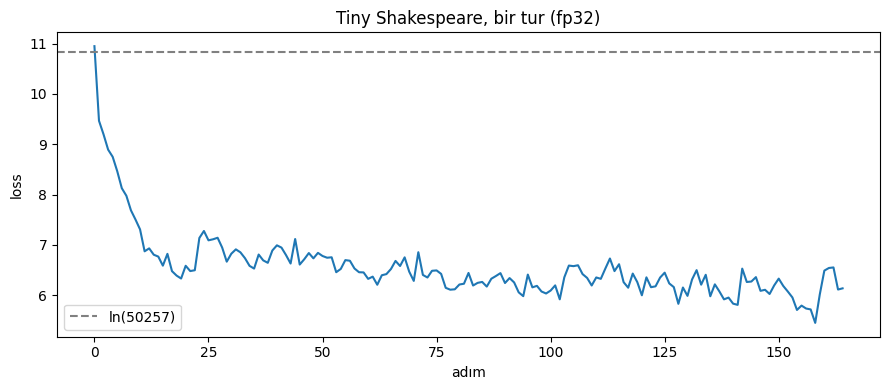

In [7]:
torch.set_float32_matmul_precision("highest")
torch.manual_seed(SEED)
model = GPT(GPTConfig()).to(device)
optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4)
loader = DataLoaderLite(sh_tokenler, H11_B, H11_T)

gecmis1 = []
t0 = time.time()
for adim in range(tur_basina_batch):
    x, y = loader.next_batch()
    x, y = x.to(device), y.to(device)
    optimizer.zero_grad()
    logits, loss = model(x, y)
    loss.backward()
    optimizer.step()
    gecmis1.append(loss.item())
    if adim % 20 == 0 or adim == tur_basina_batch - 1:
        print(f"adım {adim:4d}  loss {loss.item():.4f}")
sure1 = time.time() - t0
print(f"\nMetnin tamamı ({loader.tur} tur, {nokta(tur_basina_batch * H11_B * H11_T)} token) {tur_basina_batch} adımda bitti: {sure1:.0f} sn, {tur_basina_batch * H11_B * H11_T / sure1:.0f} token/sn")

fig, eksen = plt.subplots(figsize=(9, 4))
eksen.plot(gecmis1, linewidth=1.5)
eksen.axhline(math.log(50257), color="gray", linestyle="--", label="ln(50257)")
eksen.set_xlabel("adım")
eksen.set_ylabel("loss")
eksen.set_title("Tiny Shakespeare, bir tur (fp32)")
eksen.legend()
plt.tight_layout()
plt.show()

del model, optimizer
gc.collect()
torch.cuda.empty_cache()

Metnin tamamı bir turda 165 adım sürdü (337.920 token, 59 sn, saniyede 5.689 token). Loss 10.95'ten 6.1 civarına indi. Hafta 10'daki ezberleme testinden farkı şu: orada hep aynı batch vardı ve loss sıfıra gitti. Burada her adımda yeni bir batch geliyor, loss dalgalı (40. adımda 6.99, 160. adımda 6.49). Bazı batch'ler diğerlerinden daha zor. 6 civarındaki loss, modelin en sık token'ları ve basit kalıpları öğrendiğini ama daha fazlasını öğrenmediğini gösteriyor. Tek tur bunun için az.

## Görev 2: Eğitimi hızlandır *(Video 1:22:18 – 2:14:55)*

Bir eğitim adımının süresini ve saniyede işlenen token sayısını ölç. Sonra videodaki adımları sırayla ekle: TF32, bfloat16 (ya da float16), torch.compile, flash attention, vocab'ı 50.304'e yuvarlamak. Her adımdan sonra süreyi tabloya yaz. Senin donanımında hangi adım en çok kazandırdı?

Ölçüm şöyle: her satırda modeli sıfırdan kuruyorum, aynı batch'lerle önce 5 adım ısınma, sonra 15 adım koşup ortalama süreyi alıyorum. Her adımın sonunda `torch.cuda.synchronize()` çağırıyorum, çünkü GPU işleri sıraya koyup hemen dönüyor; beklemeden ölçersem işin bitişini değil sıraya girişini ölçerim. Batch 4 × 512: 8 GB'ta başlangıç satırının (fp32, attention matrisi bellekte) sığdığı en büyük boyut bu. 4 × 1024'te fp32 model 9 GB istedi, Windows da taşan kısmı sistem RAM'ine aktardığı için adım 10 kat yavaşladı.

Önce flash attention'a bakmam gerekti: Windows için derlenen PyTorch'ta FlashAttention kernel'i yok. `scaled_dot_product_attention` o zaman "memory-efficient" kernel'e geçiyor. O da FlashAttention gibi attention matrisini parça parça hesaplıyor ve T×T'lik matrisi belleğe hiç yazmıyor (online softmax), yani videodaki fikrin aynısı. Tabloda "flash attention" satırı bu kernel'le ölçüldü.

In [8]:
def kernel_dene(backend):
    q = torch.randn(1, 12, 256, 64, device=device, dtype=torch.bfloat16)
    try:
        with sdpa_kernel(backend):
            F.scaled_dot_product_attention(q, q, q, is_causal=True)
        return "var"
    except Exception:
        return "yok"


display(pd.DataFrame([
    ("FlashAttention", kernel_dene(SDPBackend.FLASH_ATTENTION)),
    ("Memory-efficient attention", kernel_dene(SDPBackend.EFFICIENT_ATTENTION)),
    ("cuDNN attention", kernel_dene(SDPBackend.CUDNN_ATTENTION)),
    ("Düz matematik (math)", kernel_dene(SDPBackend.MATH)),
], columns=["scaled_dot_product_attention kernel'i", "Bu kurulumda"]).style.hide(axis="index"))

scaled_dot_product_attention kernel'i,Bu kurulumda
FlashAttention,yok
Memory-efficient attention,var
cuDNN attention,var
Düz matematik (math),var


In [9]:
def hiz_olc(tf32=False, bf16=False, derle=False, flash=False, vocab=50257):
    torch.set_float32_matmul_precision("high" if tf32 else "highest")
    torch.manual_seed(SEED)
    model = GPT(GPTConfig(vocab_size=vocab, flash=flash)).to(device)
    calisan = torch.compile(model) if derle else model
    optimizer = torch.optim.AdamW(model.parameters(), lr=3e-4)
    loader = DataLoaderLite(sh_tokenler, H11_B, H11_T)
    torch.cuda.reset_peak_memory_stats()
    sureler, kayiplar = [], []
    for _ in range(HIZ_ISINMA + HIZ_ADIM):
        t0 = time.time()
        x, y = loader.next_batch()
        x, y = x.to(device), y.to(device)
        optimizer.zero_grad()
        with torch.autocast(device_type=device_type, dtype=torch.bfloat16, enabled=bf16):
            logits, loss = calisan(x, y)
        loss.backward()
        optimizer.step()
        torch.cuda.synchronize()
        sureler.append(time.time() - t0)
        kayiplar.append(loss.item())
    olcum = sureler[HIZ_ISINMA:]
    ms = 1000 * sum(olcum) / len(olcum)
    sonuc = dict(ms=ms, tok_s=H11_B * H11_T / (ms / 1000), ilk=sureler[0], bellek=torch.cuda.max_memory_allocated() / 2**30, loss=kayiplar[-1])
    del model, calisan, optimizer
    gc.collect()
    torch.cuda.empty_cache()
    if derle:
        torch._dynamo.reset()
    return sonuc


hiz_adimlari = [
    ("fp32 (başlangıç)", dict()),
    ("+ TF32", dict(tf32=True)),
    ("+ bfloat16", dict(tf32=True, bf16=True)),
    ("+ torch.compile", dict(tf32=True, bf16=True, derle=True)),
    ("+ flash attention", dict(tf32=True, bf16=True, derle=True, flash=True)),
    ("+ vocab 50.304", dict(tf32=True, bf16=True, derle=True, flash=True, vocab=50304)),
]

hiz_sonuclari = []
for ad, ayar in hiz_adimlari:
    not_ = ""
    if ayar.get("derle") and not derleme_var:
        ayar = {**ayar, "derle": False}
        not_ = "Triton yok, torch.compile atlandı"
        if ad == "+ torch.compile":
            hiz_sonuclari.append(dict(ad=ad, atlandi=True, not_=not_))
            print(f"{ad:20s} atlandı: {not_}")
            continue
    s = hiz_olc(**ayar)
    s.update(ad=ad, atlandi=False, not_=not_)
    hiz_sonuclari.append(s)
    print(f"{ad:20s} {s['ms']:7.1f} ms/adım  {s['tok_s']:8.0f} token/sn  ilk adım {s['ilk']:5.1f} sn  bellek {s['bellek']:.2f} GB  loss {s['loss']:.3f}")

torch.set_float32_matmul_precision("high")

fp32 (başlangıç)       371.2 ms/adım      5517 token/sn  ilk adım   0.5 sn  bellek 6.41 GB  loss 6.333


+ TF32                 270.2 ms/adım      7579 token/sn  ilk adım   0.3 sn  bellek 6.41 GB  loss 6.333


+ bfloat16             205.3 ms/adım      9974 token/sn  ilk adım   0.3 sn  bellek 6.05 GB  loss 6.336


+ torch.compile        147.0 ms/adım     13930 token/sn  ilk adım  24.0 sn  bellek 5.45 GB  loss 6.334


+ flash attention      133.6 ms/adım     15327 token/sn  ilk adım   1.5 sn  bellek 4.88 GB  loss 6.334


+ vocab 50.304         128.6 ms/adım     15925 token/sn  ilk adım   1.5 sn  bellek 4.81 GB  loss 6.353


Adım,ms/adım,token/sn,Bir öncekine göre,Başlangıca göre,İlk adım (sn),Tepe bellek (GB),Not
fp32 (başlangıç),371.2,5.517,-,1.00x,0.5,6.41,
+ TF32,270.2,7.579,1.37x,1.37x,0.3,6.41,
+ bfloat16,205.3,9.974,1.32x,1.81x,0.3,6.05,
+ torch.compile,147.0,13.930,1.40x,2.52x,24.0,5.45,
+ flash attention,133.6,15.327,1.10x,2.78x,1.5,4.88,
+ vocab 50.304,128.6,15.925,1.04x,2.89x,1.5,4.81,


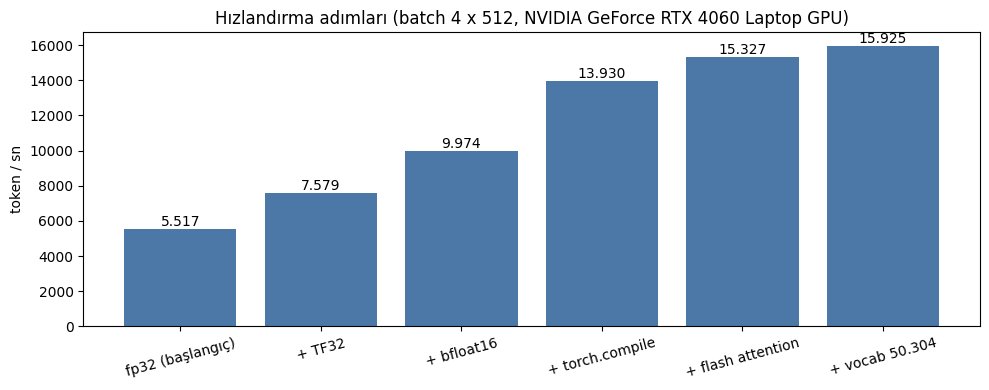

In [10]:
satirlar, onceki, ilk = [], None, None
for s in hiz_sonuclari:
    if s["atlandi"]:
        satirlar.append((s["ad"], "-", "-", "-", "-", "-", "-", s["not_"]))
        continue
    ilk = ilk or s
    satirlar.append((
        s["ad"], f"{s['ms']:.1f}", nokta(round(s["tok_s"])),
        f"{onceki['ms'] / s['ms']:.2f}x" if onceki else "-",
        f"{ilk['ms'] / s['ms']:.2f}x",
        f"{s['ilk']:.1f}", f"{s['bellek']:.2f}", s["not_"],
    ))
    onceki = s
hiz_tablosu = pd.DataFrame(satirlar, columns=["Adım", "ms/adım", "token/sn", "Bir öncekine göre", "Başlangıca göre", "İlk adım (sn)", "Tepe bellek (GB)", "Not"])
display(hiz_tablosu.style.hide(axis="index"))

olculen = [s for s in hiz_sonuclari if not s["atlandi"]]
fig, eksen = plt.subplots(figsize=(10, 4))
cubuklar = eksen.bar([s["ad"] for s in olculen], [s["tok_s"] for s in olculen], color="#4c78a8")
eksen.bar_label(cubuklar, labels=[nokta(round(s["tok_s"])) for s in olculen])
eksen.set_ylabel("token / sn")
eksen.set_title(f"Hızlandırma adımları (batch {H11_B} x {H11_T}, {torch.cuda.get_device_name(0)})")
plt.xticks(rotation=15)
plt.tight_layout()
plt.show()

**Cevap: Hangi adım ne kazandırdı?**

| Adım | ms/adım | token/sn | Kazanç |
|---|---|---|---|
| fp32 | 371.2 | 5.517 | – |
| + TF32 | 270.2 | 7.579 | 1.37x |
| + bfloat16 | 205.3 | 9.974 | 1.32x |
| + torch.compile | 147.0 | 13.930 | **1.40x** |
| + flash attention | 133.6 | 15.327 | 1.10x |
| + vocab 50.304 | 128.6 | 15.925 | 1.04x |

Hepsi birlikte adımı **2.89 kat** hızlandırdı (371 ms'den 129 ms'e) ve tepe belleği 6.41 GB'tan 4.81 GB'a indirdi. Loss her satırda aynı kaldı (6.33–6.35), yani hızlandırmalar sonucu bozmadı.

Benim donanımımda **en çok `torch.compile` kazandırdı (1.40x)**, ama TF32 (1.37x) ve bfloat16 (1.32x) çok yakın.

- **TF32:** Matris çarpımlarında sayıların mantissasını 10 bit'e kesip tensor çekirdeklerini kullanıyor. Videoda A100'de bu adım çok daha fazla kazandırıyordu. Benim tahminim, laptop kartında TF32 tensor çekirdeklerinin normal fp32'ye üstünlüğünün A100'deki kadar büyük olmaması.
- **bfloat16:** Aktivasyonlar 16 bit'e indiği için bellekten okunan ve yazılan veri yarıya iniyor. Parametreler fp32 kalıyor.
- **torch.compile:** Modeli bir bütün olarak görüp küçük işlemleri (GELU, LayerNorm, toplamalar) tek kernel'de birleştiriyor, böylece ara sonuçlar GPU belleğine gidip gelmiyor. Bellek de 6.05'ten 5.45 GB'a indi. Bedeli ilk adımda 24 sn süren derleme.
- **Flash attention:** Burada memory-efficient kernel'le. T×T'lik attention matrisi belleğe hiç yazılmadığı için bellek 5.45'ten 4.88 GB'a indi. Hız kazancı küçük (1.10x), çünkü T = 512'de attention matrisi modelin geri kalanına göre küçük. Uzun dizilerde fark büyürdü.
- **Vocab 50.304:** 50.304 = 128 × 393, yani GPU kernel'lerinin sevdiği "güzel" bir sayı. Hesap biraz arttığı hâlde adım %4 hızlandı. Fazladan 47 token'ı model hiç görmediği için olasılıkları zamanla sıfıra itiliyor.

## Görev 3: GPT-3'ün eğitim ayarları *(Video 2:14:55 – 2:46:52)*

AdamW'yi videodaki beta'larla kur, gradient clipping ekle ve her adımda gradient norm'u yazdır. Warmup'lı cosine learning rate schedule yaz ve eğrisini çiz. Weight decay'i yalnız 2 boyutlu parametrelere uygula, kaç parametreye uygulandığını yaz. Sonra gradient accumulation ekle: küçük batch'lerle büyük bir batch'in gradient'ini topla. Loss'u neden accumulation adım sayısına böldüğümüzü kendi cümlelerinle yaz.

GPT-3 makalesinin ek B'sindeki ayarlar: Adam'da β1 = 0.9, β2 = 0.95, ε = 1e-8; gradient'in toplam norm'u 1.0'da kırpılıyor; learning rate önce doğrusal ısınıyor, sonra cosine ile tepe değerin %10'una iniyor; weight decay 0.1. 124M modelde tepe learning rate 6e-4 ve batch 0.5M token.

### Weight decay hangi parametrelere uygulanıyor?

`configure_optimizers` (model kodunda) parametreleri boyutlarına göre ikiye ayırıyor. 2 boyutlu olanlar matris çarpımlarına giren ağırlıklar ve embedding'ler, weight decay bunlara uygulanıyor. 1 boyutlu olanlar (bias'lar ve LayerNorm'un ağırlık ve bias'ları) decay'siz kalıyor. Vocab'ı Görev 2'deki gibi 50.304 alıyorum.

In [11]:
model = GPT(GPTConfig(vocab_size=50304, flash=True)).to(device)
optimizer = model.configure_optimizers(WEIGHT_DECAY, MAX_LR, device_type, yazdir=True)
for i, grup in enumerate(optimizer.param_groups):
    print(f"grup {i}: weight_decay={grup['weight_decay']}  betas={grup['betas']}  eps={grup['eps']}")
del model, optimizer
torch.cuda.empty_cache()

weight decay uygulanan   :  50 tensör, 124.354.560 parametre
weight decay uygulanmayan:  98 tensör, 121.344 parametre
fused AdamW: True
grup 0: weight_decay=0.1  betas=(0.9, 0.95)  eps=1e-08
grup 1: weight_decay=0.0  betas=(0.9, 0.95)  eps=1e-08


**Cevap: Weight decay kaç parametreye uygulanıyor?**

- Uygulanan: **50 tensör, 124.354.560 parametre.** Bunlar `wte` (`lm_head` ile ortak olduğu için bir kez sayılıyor), `wpe` ve her bloktaki dört ağırlık matrisi (`c_attn`, `attn.c_proj`, `c_fc`, `mlp.c_proj`): 2 + 12 × 4 = 50.
- Uygulanmayan: **98 tensör, 121.344 parametre.** Her blokta 4 bias ile `ln_1` ve `ln_2`'nin ağırlık ve bias'ları (12 × 8 = 96), artı `ln_f`'nin iki tensörü.

Parametrelerin %99.9'una weight decay uygulanıyor. Weight decay her adımda ağırlıkları biraz sıfıra çekiyor, böylece model tek tük büyük ağırlıklara yaslanmak yerine işi birçok ağırlığa yaymak zorunda kalıyor (bir tür düzenleme). Bias'lar ve LayerNorm parametreleri ise kaydırma ve ölçekleme yapıyor, sayıları da çok az. Onları sıfıra çekmek düzenleme sağlamıyor, hatta LayerNorm'un ölçeğini küçülterek zarar verebilir. `fused=True` ile AdamW bütün parametreleri tek bir kernel'de güncelliyor.

### Warmup'lı cosine learning rate

İlk `warmup` adımda learning rate 0'dan tepe değere doğrusal çıkıyor, sonra cosine eğrisiyle `max_adim`'da tepe değerin %10'una iniyor ve orada kalıyor. Solda bu görevde kullandığım kısa eğitimin eğrisi, sağda Karpathy'nin 10B token'lık eğitimindeki ayar (715 adım warmup, 19.073 adım).

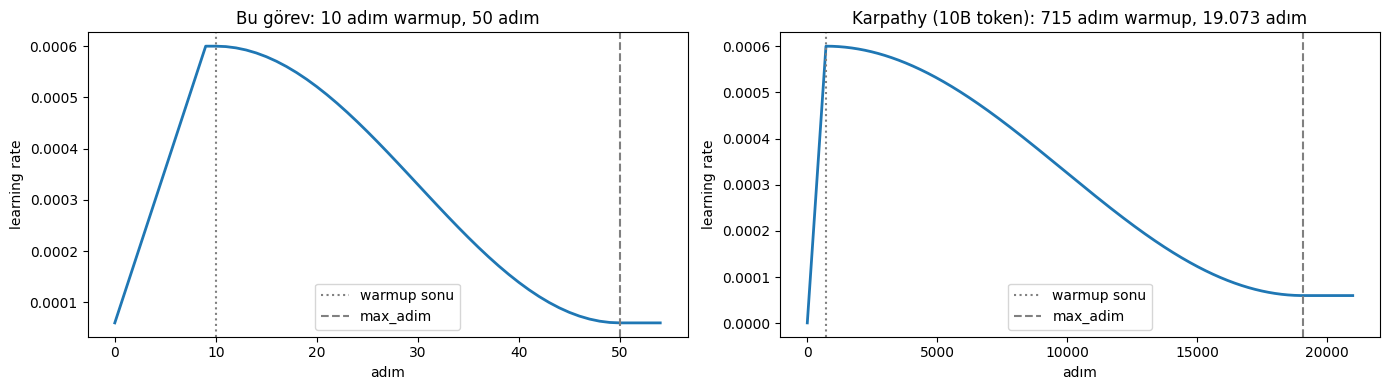

In [12]:
def lr_hesapla(adim, max_lr, min_lr, warmup, max_adim):
    if adim < warmup:
        return max_lr * (adim + 1) / warmup
    if adim > max_adim:
        return min_lr
    oran = (adim - warmup) / (max_adim - warmup)
    katsayi = 0.5 * (1.0 + math.cos(math.pi * oran))
    return min_lr + katsayi * (max_lr - min_lr)


fig, eksenler = plt.subplots(1, 2, figsize=(14, 4))
for eksen, (baslik, warmup, max_adim) in zip(eksenler, [
    (f"Bu görev: {H11_WARMUP} adım warmup, {H11_ADIM} adım", H11_WARMUP, H11_ADIM),
    ("Karpathy (10B token): 715 adım warmup, 19.073 adım", 715, 19073),
]):
    adimlar = list(range(int(max_adim * 1.1)))
    eksen.plot(adimlar, [lr_hesapla(a, MAX_LR, MIN_LR, warmup, max_adim) for a in adimlar], linewidth=2)
    eksen.axvline(warmup, color="gray", linestyle=":", label="warmup sonu")
    eksen.axvline(max_adim, color="gray", linestyle="--", label="max_adim")
    eksen.set_title(baslik)
    eksen.set_xlabel("adım")
    eksen.set_ylabel("learning rate")
    eksen.legend()
plt.tight_layout()
plt.show()

### Gradient accumulation neden loss'u bölüyor?

Önce küçük bir kontrol yaptım. Küçük bir modelde (2 blok, 64 boyut, `float64` ile, yuvarlama hatası karışmasın diye) 8 dizilik bir batch'in gradient'ini üç yoldan hesaplıyorum:

1. 8 diziyi tek seferde verip `backward()`.
2. 4 parçaya bölüp (her parça 2 dizi) her parçada `backward()`, loss'u bölmeden. PyTorch gradient'leri `+=` ile biriktiriyor.
3. Aynısı, ama her parçanın loss'unu 4'e bölerek.

In [13]:
torch.manual_seed(SEED)
kucuk = GPT(GPTConfig(block_size=64, vocab_size=50304, n_layer=2, n_head=2, n_embd=64)).to(device).double()
x, y = DataLoaderLite(sh_tokenler, 8, 64).next_batch()
x, y = x.to(device), y.to(device)
parca = 4


def gradyan(bolerek=None):
    kucuk.zero_grad()
    if bolerek is None:
        _, loss = kucuk(x, y)
        loss.backward()
    else:
        for i in range(parca):
            _, loss = kucuk(x[i * 2:(i + 1) * 2], y[i * 2:(i + 1) * 2])
            if bolerek:
                loss = loss / parca
            loss.backward()
    return torch.cat([p.grad.flatten() for p in kucuk.parameters()]).clone()


g_tek = gradyan()
g_bolmesiz = gradyan(bolerek=False)
g_bolerek = gradyan(bolerek=True)
display(pd.DataFrame([
    ("Tek seferde (8 dizi)", f"{g_tek.norm().item():.6f}", "-", "-"),
    ("4 parça, loss bölünmeden", f"{g_bolmesiz.norm().item():.6f}", f"{(g_bolmesiz - g_tek).abs().max().item():.2e}", f"{(g_bolmesiz.norm() / g_tek.norm()).item():.4f}"),
    ("4 parça, loss / 4", f"{g_bolerek.norm().item():.6f}", f"{(g_bolerek - g_tek).abs().max().item():.2e}", f"{(g_bolerek.norm() / g_tek.norm()).item():.4f}"),
], columns=["Yöntem", "Gradient norm", "Tek seferden en büyük fark", "Norm oranı"]).style.hide(axis="index"))
del kucuk

Yöntem,Gradient norm,Tek seferden en büyük fark,Norm oranı
Tek seferde (8 dizi),2.181718,-,-
"4 parça, loss bölünmeden",8.726870,9.44e-01,4.0000
"4 parça, loss / 4",2.181718,1.11e-16,1.0000


**Cevap: Loss'u neden accumulation adım sayısına bölüyoruz?**

Tablo cevabı veriyor: bölmeden toplanan gradient'in norm'u **tam 4 kat** büyük çıktı (8.73 = 4 × 2.18). Bölünce tek seferdekiyle farkı 1.1e-16, yani `float64`'ün yuvarlama hatası kadar.

Sebebi `cross_entropy`'nin toplam değil **ortalama** döndürmesi. 8 diziyi tek seferde verince loss 8 × T token'ın ortalaması oluyor. 4 parçaya bölünce her parçanın loss'u kendi 2 × T token'ının ortalaması. `backward()` gradient'leri her seferinde `+=` ile üst üste koyduğu için sonunda 4 ortalamanın **toplamını** almış oluyoruz, bu da büyük batch'in ortalamasının 4 katı. Her parçanın loss'unu 4'e bölünce 4 ortalamanın ortalamasını almış oluyoruz, o da tam olarak büyük batch'in ortalaması.

Bölmeyi unutsam kod hata vermez ama gradient `grad_accum` kat büyük olur. Learning rate'i gizlice o kadar artırmak gibi bir etkisi olur. Gradient clipping de her adımda devreye girer, çünkü norm hep 1'in üstünde çıkar.

### Hepsi bir arada: Tiny Shakespeare'de eğitim

Şimdi hepsini birleştiriyorum: TF32, bfloat16, torch.compile, flash attention, vocab 50.304, GPT-3'ün AdamW ayarları, weight decay, gradient clipping, cosine learning rate ve gradient accumulation. Toplam batch 2^15 = 32.768 token, micro-batch 4 × 1024 = 4.096 token, yani her adımda 8 micro-batch'in gradient'i toplanıyor. Her adımda loss, learning rate, gradient norm ve süreyi yazdırıyorum. İlk adım torch.compile'ın derleme süresini de içeriyor.

toplam batch 32.768 token = 8 micro-batch x (4 x 1024)



adım   0 | loss 10.9401 | lr 6.00e-05 | norm 29.875 |    3062 ms |   10701 token/sn


adım   1 | loss 9.6733 | lr 1.20e-04 | norm  9.544 |    1396 ms |   23468 token/sn


adım   2 | loss 9.2117 | lr 1.80e-04 | norm  4.928 |    1382 ms |   23704 token/sn


adım   3 | loss 9.8854 | lr 2.40e-04 | norm  8.510 |    1410 ms |   23243 token/sn


adım   4 | loss 9.2515 | lr 3.00e-04 | norm  4.422 |    1371 ms |   23893 token/sn


... (41 outputs left out)

adım  46 | loss 5.9527 | lr 7.32e-05 | norm  0.589 |    1455 ms |   22518 token/sn


adım  47 | loss 5.9764 | lr 6.75e-05 | norm  0.443 |    1496 ms |   21911 token/sn


adım  48 | loss 6.0710 | lr 6.33e-05 | norm  0.709 |    1464 ms |   22383 token/sn


adım  49 | loss 5.9423 | lr 6.08e-05 | norm  0.696 |    1493 ms |   21953 token/sn

İlk 2 adım hariç ortanca hız: 23246 token/sn  |  Shakespeare'in üzerinden 4 tur geçildi


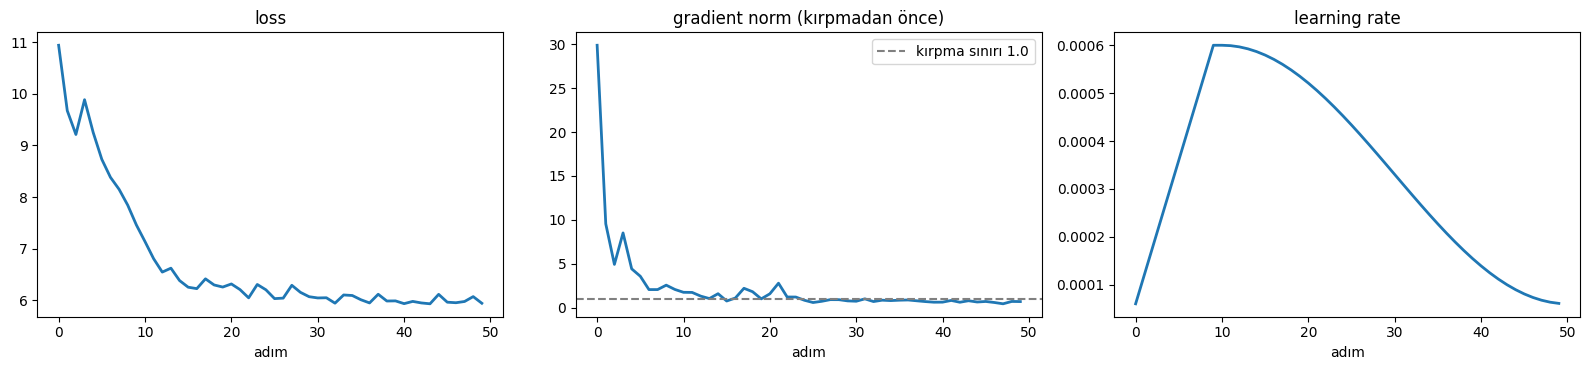

In [14]:
grad_accum = H11_TOPLAM_BATCH // (B * T)
assert H11_TOPLAM_BATCH % (B * T) == 0
print(f"toplam batch {nokta(H11_TOPLAM_BATCH)} token = {grad_accum} micro-batch x ({B} x {T})\n")

torch.manual_seed(SEED)
model = GPT(GPTConfig(vocab_size=50304, flash=True)).to(device)
optimizer = model.configure_optimizers(WEIGHT_DECAY, MAX_LR, device_type)
calisan = torch.compile(model) if derleme_var else model
loader = DataLoaderLite(sh_tokenler, B, T)

h11_log = []
for adim in range(H11_ADIM):
    t0 = time.time()
    optimizer.zero_grad()
    loss_toplam = 0.0
    for _ in range(grad_accum):
        x, y = loader.next_batch()
        x, y = x.to(device), y.to(device)
        with torch.autocast(device_type=device_type, dtype=torch.bfloat16):
            logits, loss = calisan(x, y)
        loss = loss / grad_accum
        loss_toplam += loss.detach()
        loss.backward()
    norm = torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
    lr = lr_hesapla(adim, MAX_LR, MIN_LR, H11_WARMUP, H11_ADIM)
    for grup in optimizer.param_groups:
        grup["lr"] = lr
    optimizer.step()
    torch.cuda.synchronize()
    dt = time.time() - t0
    h11_log.append(dict(adim=adim, loss=loss_toplam.item(), lr=lr, norm=norm.item(), dt=dt, tok_s=H11_TOPLAM_BATCH / dt))
    print(f"adım {adim:3d} | loss {loss_toplam.item():.4f} | lr {lr:.2e} | norm {norm.item():6.3f} | {dt * 1000:7.0f} ms | {H11_TOPLAM_BATCH / dt:7.0f} token/sn")

h11_df = pd.DataFrame(h11_log)
h11_hiz = h11_df["tok_s"].iloc[2:].median()
print(f"\nİlk 2 adım hariç ortanca hız: {h11_hiz:.0f} token/sn  |  Shakespeare'in üzerinden {loader.tur} tur geçildi")

fig, eksenler = plt.subplots(1, 3, figsize=(16, 3.8))
for eksen, sutun, baslik in zip(eksenler, ["loss", "norm", "lr"], ["loss", "gradient norm (kırpmadan önce)", "learning rate"]):
    eksen.plot(h11_df["adim"], h11_df[sutun], linewidth=2)
    eksen.set_title(baslik)
    eksen.set_xlabel("adım")
eksenler[1].axhline(1.0, color="gray", linestyle="--", label="kırpma sınırı 1.0")
eksenler[1].legend()
plt.tight_layout()
plt.show()

del model, optimizer, calisan
gc.collect()
torch.cuda.empty_cache()
torch._dynamo.reset()

50 adımda loss 10.94'ten 5.94'e indi. Gradient norm ilk adımda **29.9** çıktı: rastgele modelin gradient'leri çok büyük. Clipping olmasa ilk güncelleme modeli fazla sarsardı, clipping onu 1.0'a indirdi. Learning rate'in ilk 10 adımda yavaş yavaş artması (warmup) da aynı işe yarıyor. Norm 15. adımdan sonra çoğunlukla 1'in altına indi. Arada tek tük sıçramalar var (3. adımda 8.5, 21. adımda 2.8), clipping bunları da kesti. Learning rate grafiği yukarıdaki cosine eğrisinin aynısı.

Hız ortanca **23.246 token/sn**, bir adım 32.768 token ve yaklaşık 1.4 sn. Görev 2'deki tabloda en hızlı satır 15.925 token/sn'ydi. Aynı ayarlarla burada daha hızlı, çünkü micro-batch 4 × 512 yerine 4 × 1024: GPU'ya bir kerede daha büyük iş verince daha verimli çalışıyor. İlk adım sadece 3 sn sürdü, çünkü Triton kernel'leri Görev 2'deki derlemeden diskte önbellekte duruyordu. Model Shakespeare'in üzerinden 4 tur geçti. Hafta 12'deki eğitim süresini bu ölçtüğüm hızdan hesaplıyorum.

## Görev 4 (ek, b): Türkçe metinde iki tokenizer *(Videoda yok)*

Aynı modeli Türkçe metinde iki kez eğit: bir kez GPT-2 tokenizer'ıyla, bir kez hafta 9'da yazdığın tokenizer'la. Aynı süre içinde hangisi metni daha çok görüyor, loss'ları nasıl karşılaştırırsın?

Metin olarak Sabahattin Ali'nin *Kürk Mantolu Madonna*'sını (1943 baskısının OCR metni) kullandım. Sabahattin Ali 1948'de öldüğü için eser kamu malı. Önce Hafta 9'daki gibi temizliyorum: NFC, satır sonundaki `¬` ile bölünmüş kelimeleri birleştirme, tipografik tırnakları düz tırnağa çevirme, tek satır sonlarını boşluk yapma. Kapak ve künye kısmını atıp ilk %90'ı eğitim, son %10'u doğrulama için ayırıyorum.

In [15]:
ESLEME = {"‘": "'", "’": "'", "´": "'", "“": '"', "”": '"', "«": '"', "»": '"', "–": "-", "—": "-", "…": "...", "\t": " ", "\xa0": " "}


def roman_temizle(ham):
    t = unicodedata.normalize("NFC", ham).replace("\r\n", "\n")
    t = t.translate(str.maketrans(ESLEME))
    t = re.sub(r"¬\s*", "", t)
    t = re.sub(r"[ ]*\n[ ]*", "\n", t)
    t = re.sub(r"(?<!\n)\n(?!\n)", " ", t)
    t = re.sub(r"\n{2,}", "\n", t)
    t = re.sub(r" {2,}", " ", t)
    return t.strip()


with open(ROMAN_YOLU, encoding="utf-8") as f:
    roman = roman_temizle(f.read())
roman = roman[roman.find("Şimdiye kadar"):]
bolme = int(len(roman) * 0.9)
tr_train, tr_val = roman[:bolme], roman[bolme:]
print(f"Temiz metin: {nokta(len(roman))} karakter, {nokta(len(roman.encode('utf-8')))} byte, {len(set(roman))} farklı karakter")
print(f"Eğitim: {nokta(len(tr_train))} karakter  |  doğrulama: {nokta(len(tr_val))} karakter")

Temiz metin: 304.276 karakter, 333.096 byte, 102 farklı karakter
Eğitim: 273.848 karakter  |  doğrulama: 30.428 karakter


Tokenizer, Hafta 9'da yazdığım regex'li BPE: metni önce GPT-4'ün deseniyle parçalara bölüyor, birleştirmeleri parçaların içinde yapıyor. Vocab yine 512 (256 byte + 256 birleştirme). Bu sefer romanın eğitim kısmında eğittim. `encode`'u hızlandırmak için aynı parçayı bir kez token'layıp sonucu sözlükte tutuyorum.

In [16]:
GPT4_DESEN = r"""'(?i:[sdmt]|ll|ve|re)|[^\r\n\p{L}\p{N}]?+\p{L}+|\p{N}{1,3}| ?[^\s\p{L}\p{N}]++[\r\n]*|\s*[\r\n]|\s+(?!\S)|\s+"""


def merge(ids, pair, idx):
    yeni, i = [], 0
    while i < len(ids):
        if i < len(ids) - 1 and ids[i] == pair[0] and ids[i + 1] == pair[1]:
            yeni.append(idx)
            i += 2
        else:
            yeni.append(ids[i])
            i += 1
    return yeni


def vocab_olustur(merges):
    vocab = {i: bytes([i]) for i in range(256)}
    for (a, b), idx in merges.items():
        vocab[idx] = vocab[a] + vocab[b]
    return vocab


def egit_regex(metin, vocab_size, desen=GPT4_DESEN):
    sayac_parca = Counter(regex.findall(desen, metin))
    parcalar = [list(p.encode("utf-8")) for p in sayac_parca]
    agirlik = list(sayac_parca.values())
    merges = {}
    for idx in range(256, vocab_size):
        stats = {}
        for p, w in zip(parcalar, agirlik):
            for a, b in zip(p, p[1:]):
                stats[(a, b)] = stats.get((a, b), 0) + w
        if not stats:
            break
        pair = max(stats, key=stats.get)
        parcalar = [merge(p, pair, idx) for p in parcalar]
        merges[pair] = idx
    return merges, vocab_olustur(merges)


def encode_parca(parca, merges):
    ids = list(parca.encode("utf-8"))
    while len(ids) >= 2:
        pair = min(zip(ids, ids[1:]), key=lambda p: merges.get(p, float("inf")))
        if pair not in merges:
            break
        ids = merge(ids, pair, merges[pair])
    return ids


def encode_regex(metin, merges, onbellek, desen=GPT4_DESEN):
    ids = []
    for p in regex.findall(desen, metin):
        if p not in onbellek:
            onbellek[p] = encode_parca(p, merges)
        ids.extend(onbellek[p])
    return ids


def decode(ids, vocab):
    return b"".join(vocab[i] for i in ids).decode("utf-8", errors="replace")


t0 = time.time()
merges_tr, vocab_tr = egit_regex(tr_train, TR_VOCAB)
print(f"BPE eğitimi: {len(merges_tr)} birleştirme, {time.time() - t0:.0f} sn")

onbellek = {}
tok_kendi = {"train": encode_regex(tr_train, merges_tr, onbellek), "val": encode_regex(tr_val, merges_tr, onbellek)}
tok_gpt2 = {"train": enc.encode_ordinary(tr_train), "val": enc.encode_ordinary(tr_val)}
assert decode(tok_kendi["val"], vocab_tr) == tr_val and enc.decode(tok_gpt2["val"]) == tr_val

bayt_gpt2 = torch.tensor([len(enc.decode_single_token_bytes(i)) for i in range(enc.n_vocab)] + [0] * (50304 - enc.n_vocab))
bayt_kendi = torch.tensor([len(vocab_tr[i]) for i in range(TR_VOCAB)])

satirlar = []
for ad, toklar, vocab_boyu in [("GPT-2 tokenizer'ı", tok_gpt2, enc.n_vocab), ("Hafta 9 tokenizer'ı (Türkçe BPE)", tok_kendi, TR_VOCAB)]:
    for parca in ("train", "val"):
        metin = tr_train if parca == "train" else tr_val
        satirlar.append((ad, vocab_boyu, parca, nokta(len(metin.encode("utf-8"))), nokta(len(toklar[parca])), f"{len(metin.encode('utf-8')) / len(toklar[parca]):.3f}"))
display(pd.DataFrame(satirlar, columns=["Tokenizer", "Vocab", "Bölüm", "Byte", "Token", "Byte / token"]).style.hide(axis="index"))

cumle = "Raif Efendi, kürk mantolu kadının resmine bakarken gözlerini kaybetti."
print(f"\nGPT-2  ({len(enc.encode(cumle))} token): " + " | ".join(enc.decode([t]) for t in enc.encode(cumle)))
print(f"Hafta 9 ({len(encode_regex(cumle, merges_tr, {}))} token): " + " | ".join(decode([t], vocab_tr) for t in encode_regex(cumle, merges_tr, {})))

BPE eğitimi: 256 birleştirme, 9 sn


Tokenizer,Vocab,Bölüm,Byte,Token,Byte / token
GPT-2 tokenizer'ı,50257,train,299.813,138.488,2.165
GPT-2 tokenizer'ı,50257,val,33.283,15.393,2.162
Hafta 9 tokenizer'ı (Türkçe BPE),512,train,299.813,137.038,2.188
Hafta 9 tokenizer'ı (Türkçe BPE),512,val,33.283,15.472,2.151



GPT-2  (33 token): Ra | if |  E | f | endi | , |  k | ür | k |  mant | ol | u |  k | ad | ı | n | ı | n |  res | mine |  b | ak | ark | en |  g | ö | z | ler | ini |  kay | b | etti | .
Hafta 9 (36 token): R | a | if |  E | f | en | di | , |  k | ür | k |  m | an | t | ol | u |  kad | ın | ın |  r | es | m | ine |  bak | ar | k | en |  göz | ler | ini |  k | ay | b | et | ti | .


**Loss'ları nasıl karşılaştıracağım?** İki model aynı metni farklı sayıda token'la görüyor. Token başına loss doğrudan karşılaştırılamaz: GPT-2 tokenizer'ında bir token ortalama daha çok byte tutuyor, yani her tahmin daha zor ama daha az tahmin yapılıyor. Ortak birim metnin kendisi olmalı. Bu yüzden doğrulama metnindeki toplam loss'u (nats) metnin byte sayısına bölüp 2 tabanına çeviriyorum: **byte başına bit (bits per byte, bpb)**. Bu, "modeli kullanarak bu metni sıkıştırsam byte başına kaç bit harcardım" demek ve tokenizer'dan bağımsız.

İki modeli aynı koşullarda eğitiyorum: aynı 124M mimari (vocab hariç), aynı batch (4 × 512 token), bfloat16, flash attention, aynı AdamW ayarları (lr 3e-4, ilk 20 adım warmup), ve aynı süre: **90 saniye** saf eğitim (değerlendirme süreye sayılmıyor). torch.compile'ı burada kullanmadım, iki model için de derleme süresi eşit olmayabilirdi. Her 20 adımda doğrulama metninin tamamında token başına loss ve bpb ölçüyorum.

In [17]:
def sureli_egit(ad, tokenler, vocab_size, bayt, sure=TR_SURE):
    torch.manual_seed(SEED)
    model = GPT(GPTConfig(vocab_size=vocab_size, flash=True)).to(device)
    optimizer = model.configure_optimizers(WEIGHT_DECAY, TR_LR, device_type)
    loader = DataLoaderLite(tokenler["train"], H11_B, H11_T)
    n = (len(tokenler["val"]) - 1) // H11_T
    vt = torch.tensor(tokenler["val"], dtype=torch.long)
    val_x = vt[: n * H11_T].view(n, H11_T).to(device)
    val_y = vt[1 : n * H11_T + 1].view(n, H11_T).to(device)
    val_bayt = bayt[val_y.cpu()].sum().item()

    @torch.no_grad()
    def degerlendir():
        model.eval()
        toplam = 0.0
        for i in range(0, n, H11_B):
            with torch.autocast(device_type=device_type, dtype=torch.bfloat16):
                logits, _ = model(val_x[i:i + H11_B])
            toplam += F.cross_entropy(logits.float().view(-1, logits.size(-1)), val_y[i:i + H11_B].reshape(-1), reduction="sum").item()
        model.train()
        return toplam / (n * H11_T), toplam / (math.log(2) * val_bayt)

    gecmis = []
    gecen, adim, gorulen_token, gorulen_bayt = 0.0, 0, 0, 0
    while gecen < sure:
        if adim % TR_DEGER_HER == 0:
            gecmis.append((adim, gecen, gorulen_bayt, *degerlendir()))
        t0 = time.time()
        x, y = loader.next_batch()
        gorulen_bayt += bayt[y].sum().item()
        gorulen_token += y.numel()
        x, y = x.to(device), y.to(device)
        for grup in optimizer.param_groups:
            grup["lr"] = TR_LR * min(1.0, (adim + 1) / 20)
        optimizer.zero_grad()
        with torch.autocast(device_type=device_type, dtype=torch.bfloat16):
            _, loss = model(x, y)
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()
        torch.cuda.synchronize()
        gecen += time.time() - t0
        adim += 1
    gecmis.append((adim, gecen, gorulen_bayt, *degerlendir()))
    gecmis = pd.DataFrame(gecmis, columns=["adim", "sure", "bayt", "val_loss", "val_bpb"])
    en_iyi = gecmis.loc[gecmis["val_bpb"].idxmin()]
    print(f"{ad}: {adim} adım, {gorulen_token / gecen:.0f} token/sn, en iyi val bpb {en_iyi['val_bpb']:.3f} (adım {int(en_iyi['adim'])}), son val bpb {gecmis['val_bpb'].iloc[-1]:.3f}")
    sonuc = dict(
        ad=ad, vocab=vocab_size, parametre=sum(p.numel() for p in model.parameters()), adim=adim, sure=gecen,
        token=gorulen_token, bayt=gorulen_bayt, tok_s=gorulen_token / gecen, bayt_s=gorulen_bayt / gecen,
        tur=gorulen_token / len(tokenler["train"]), gecmis=gecmis, en_iyi=en_iyi,
    )
    del model, optimizer
    gc.collect()
    torch.cuda.empty_cache()
    return sonuc


tr_sonuclar = [
    sureli_egit("GPT-2 tokenizer'ı", tok_gpt2, 50304, bayt_gpt2),
    sureli_egit("Hafta 9 tokenizer'ı", tok_kendi, TR_VOCAB, bayt_kendi),
]

GPT-2 tokenizer'ı: 752 adım, 17098 token/sn, en iyi val bpb 2.457 (adım 260), son val bpb 3.351


Hafta 9 tokenizer'ı: 1127 adım, 25637 token/sn, en iyi val bpb 2.495 (adım 200), son val bpb 4.361


Tokenizer,Vocab,Parametre,Adım,token/sn,Görülen token,Görülen metin (byte),byte/sn,Tur (epoch),En iyi val loss / token,En iyi val bpb,En iyi adım,Son val bpb
GPT-2 tokenizer'ı,50304,124.475.904,752,17.098,1.540.096,3.334.145,37.016,11.1,3.684,2.457,260,3.351
Hafta 9 tokenizer'ı,512,86.235.648,1127,25.637,2.308.096,5.049.390,56.086,16.8,3.730,2.495,200,4.361


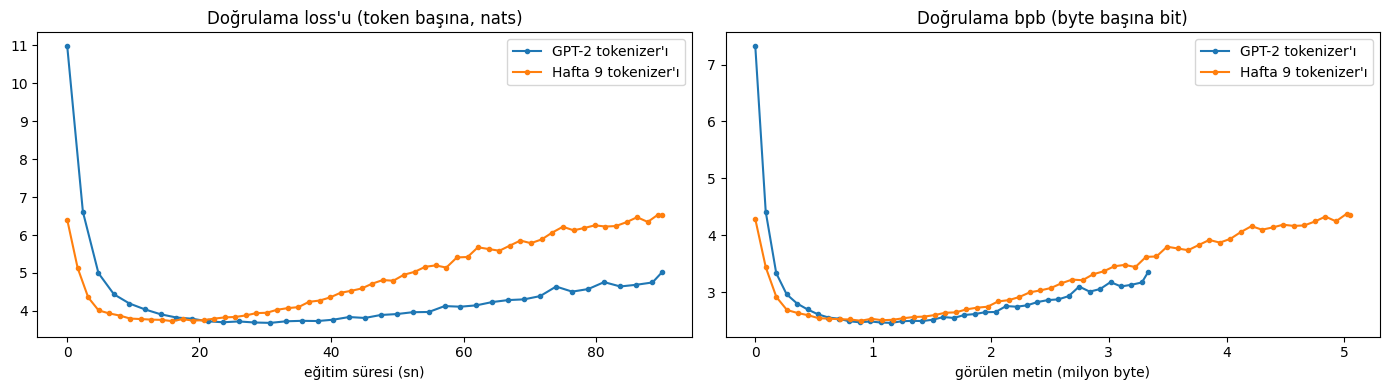

In [18]:
display(pd.DataFrame([(
    s["ad"], s["vocab"], nokta(s["parametre"]), s["adim"], nokta(round(s["tok_s"])), nokta(s["token"]),
    nokta(s["bayt"]), nokta(round(s["bayt_s"])), f"{s['tur']:.1f}",
    f"{s['en_iyi']['val_loss']:.3f}", f"{s['en_iyi']['val_bpb']:.3f}", int(s["en_iyi"]["adim"]), f"{s['gecmis']['val_bpb'].iloc[-1]:.3f}",
) for s in tr_sonuclar], columns=[
    "Tokenizer", "Vocab", "Parametre", "Adım", "token/sn", "Görülen token", "Görülen metin (byte)", "byte/sn", "Tur (epoch)",
    "En iyi val loss / token", "En iyi val bpb", "En iyi adım", "Son val bpb",
]).style.hide(axis="index"))

fig, eksenler = plt.subplots(1, 2, figsize=(14, 4))
for s in tr_sonuclar:
    eksenler[0].plot(s["gecmis"]["sure"], s["gecmis"]["val_loss"], marker="o", markersize=3, label=s["ad"])
    eksenler[1].plot(s["gecmis"]["bayt"] / 1e6, s["gecmis"]["val_bpb"], marker="o", markersize=3, label=s["ad"])
eksenler[0].set_title("Doğrulama loss'u (token başına, nats)")
eksenler[0].set_xlabel("eğitim süresi (sn)")
eksenler[1].set_title("Doğrulama bpb (byte başına bit)")
eksenler[1].set_xlabel("görülen metin (milyon byte)")
for eksen in eksenler:
    eksen.legend()
plt.tight_layout()
plt.show()

**Cevap: Aynı süre içinde hangisi metni daha çok görüyor, loss'ları nasıl karşılaştırırım?**

İlk şaşırtıcı sonuç sıkıştırma oldu. Hafta 9 tokenizer'ı Türkçe metni GPT-2 tokenizer'ıyla **neredeyse aynı** oranda sıkıştırıyor: byte başına token eğitim kısmında 2.188 ile 2.165, doğrulamada 2.151 ile 2.162. Yani 512 token'lık Türkçe sözlüğüm, 50.257 token'lık İngilizce ağırlıklı sözlük kadar işe yarıyor. GPT-2'nin sözlüğünün büyük kısmı Türkçede hiç kullanılmıyor.

**Daha çok metni Hafta 9 tokenizer'ı görüyor.** 90 saniyede **5.05 milyon byte** gördü, GPT-2 tokenizer'ıyla eğitilen model ise **3.33 milyon byte**, yani 1.5 kat fark. Sebep, her token'ın aşağı yukarı aynı miktarda metin tutması ama küçük vocab'lı modelin daha hızlı olması: 25.637 token/sn'ye karşı 17.098 token/sn. 512 token'lık vocab'ta `wte` ve `lm_head` 50.304 × 768 yerine 512 × 768. Model 124M'den 86M'e iniyor, en pahalı işlemlerden biri olan logits hesabı (2048 × 50.304'lük matris) neredeyse kayboluyor.

**Loss'ları byte başına bit (bpb) ile karşılaştırdım.** Token başına loss burada yanıltıcı. Adım 0'da GPT-2 tokenizer'lı modelin loss'u 10.96, Hafta 9 tokenizer'lı modelin 6.4. Ama bu sadece ln(50304) ile ln(512) arasındaki fark, ikisi de hiçbir şey bilmiyor. Bpb'de ikisi de yaklaşık 7.3 ve 4.3'ten başlayıp aynı yere iniyor.

| | En iyi val bpb | En iyi olduğu an | Son val bpb |
|---|---|---|---|
| GPT-2 tokenizer'ı | **2.457** | ~30. sn, adım 260 | 3.351 |
| Hafta 9 tokenizer'ı | 2.495 | ~18. sn, adım 200 | 4.361 |

En iyi noktada GPT-2 tokenizer'ı %1.5 daha iyi, yani fark çok küçük. Sağdaki grafikte iki eğri "görülen metin" eksenine göre neredeyse üst üste. **Aynı miktarda metin gören iki model aynı şeyi öğreniyor, tokenizer'ın kazandırdığı şey hız.** Hafta 9 tokenizer'ı en iyi noktasına 12 saniye önce ulaştı.

İkisi de sonra ezberlemeye başladı. Roman sadece ~140 bin token ve 124M'lik model 11 ile 17 tur geçince doğrulama loss'u yükseldi. Daha hızlı olan model ezberlemeye de daha hızlı girdi, bu yüzden son değeri daha kötü. Karşılaştırmayı "en iyi bpb" ve "görülen metne göre eğri" üzerinden yapmak bu yüzden daha adil. Daha büyük bir Türkçe veride (Görev 5'teki gibi) ezberleme olmazdı ve Hafta 9 tokenizer'ının hız avantajı doğrudan daha düşük loss'a dönüşürdü.

# Hafta 12: Gerçek veride eğitim ve HellaSwag

## Görev 1: Veriyi hazırla *(Video 3:10:21 – 3:23:10)*

FineWeb-Edu'dan küçük bir parça (birkaç on milyon token yeterli) ya da kendi Türkçe metnini GPT-2 tokenizer'ıyla token'la. Token'ları dosyalara böl ve data loader'ını bu dosyalardan okuyacak hâle getir. Bir dosyayı doğrulama için ayır.

Karpathy'nin `fineweb.py`'si gibi yaptım, sadece küçülttüm. FineWeb-Edu'nun `sample-10BT` alt kümesini `streaming=True` ile okuyorum, yani 2 GB'lık parquet dosyalarını indirmeden belgeleri sırayla çekiyorum. Her belgenin başına `<|endoftext|>` koyup GPT-2 tokenizer'ıyla token'lıyorum (`encode_ordinary_batch` 1024 belgeyi birden, 8 thread'le token'lıyor). Token'ları 10 milyonluk shard'lara dolduruyorum, bir belge shard sınırına denk gelirse kalanı sonraki shard'a geçiyor. Token id'leri 50.257'den küçük olduğu için `uint16` yetiyor, böylece her shard diskte 20 MB. İlk shard doğrulama, kalanlar eğitim.

Kaç shard gerektiğini Hafta 11'de ölçtüğüm hızdan hesapladım: 4 × 1024 micro-batch'le saniyede yaklaşık 23 bin token, bir saatte yaklaşık 85 milyon token. 10 shard aldım: 10M doğrulama, 90M eğitim, bir saatlik eğitim verinin üzerinden yaklaşık bir kez geçiyor. Shard'lar notebook'un yanındaki `veri_fineweb_edu/` klasörüne yazılıyor ve klasör `.gitignore`'da. Dosyalar zaten varsa yeniden indirmiyorum.

In [19]:
def belge_tokenleri(kaynak, paket_boyu=1024):
    paket = []
    for ornek in kaynak:
        paket.append(ornek["text"])
        if len(paket) == paket_boyu:
            yield from enc.encode_ordinary_batch(paket, num_threads=8)
            paket = []
    if paket:
        yield from enc.encode_ordinary_batch(paket, num_threads=8)


def shard_yaz(klasor, onek, kaynak_ad, kaynak_alt, shard_sayisi, shard_token=SHARD_TOKEN):
    os.makedirs(klasor, exist_ok=True)
    dosyalar = [os.path.join(klasor, f"{onek}_{'val' if i == 0 else 'train'}_{i:06d}.npy") for i in range(shard_sayisi)]
    ozet_yolu = os.path.join(klasor, "ozet.json")
    if all(os.path.exists(d) for d in dosyalar) and os.path.exists(ozet_yolu):
        print(f"{shard_sayisi} shard zaten hazır, yeniden indirilmedi.")
        with open(ozet_yolu, encoding="utf-8") as f:
            return dosyalar, json.load(f)

    kaynak = load_dataset(kaynak_ad, name=kaynak_alt, split="train", streaming=True)
    tampon = np.empty(shard_token, dtype=np.uint16)
    dolu, shard, uzunluklar = 0, 0, []
    t0 = time.time()
    for tokenler in belge_tokenleri(kaynak):
        dizi = np.array([EOT] + tokenler, dtype=np.int64)
        assert dizi.max() < 2**16
        uzunluklar.append(len(dizi))
        while len(dizi) > 0 and shard < shard_sayisi:
            sigan = min(shard_token - dolu, len(dizi))
            tampon[dolu:dolu + sigan] = dizi[:sigan]
            dolu += sigan
            dizi = dizi[sigan:]
            if dolu == shard_token:
                np.save(dosyalar[shard], tampon)
                print(f"  {os.path.basename(dosyalar[shard])} yazıldı  |  {len(uzunluklar):,} belge  |  {time.time() - t0:.0f} sn".replace(",", "."))
                shard += 1
                dolu = 0
        if shard == shard_sayisi:
            break
    ozet = dict(belge=len(uzunluklar), uzunluklar=uzunluklar, sure=time.time() - t0)
    with open(ozet_yolu, "w", encoding="utf-8") as f:
        json.dump(ozet, f)
    return dosyalar, ozet


edu_dosyalar, edu_ozet = shard_yaz(VERI_EDU, "edufineweb", "HuggingFaceFW/fineweb-edu", "sample-10BT", EDU_SHARD)

  edufineweb_val_000000.npy yazıldı  |  9.671 belge  |  5 sn


  edufineweb_train_000001.npy yazıldı  |  19.441 belge  |  6 sn


  edufineweb_train_000002.npy yazıldı  |  27.975 belge  |  8 sn


  edufineweb_train_000003.npy yazıldı  |  38.185 belge  |  10 sn


  edufineweb_train_000004.npy yazıldı  |  47.453 belge  |  12 sn


  edufineweb_train_000005.npy yazıldı  |  57.073 belge  |  14 sn


  edufineweb_train_000006.npy yazıldı  |  66.667 belge  |  16 sn


  edufineweb_train_000007.npy yazıldı  |  75.805 belge  |  18 sn


  edufineweb_train_000008.npy yazıldı  |  85.927 belge  |  20 sn


  edufineweb_train_000009.npy yazıldı  |  95.821 belge  |  22 sn


,Değer
Shard sayısı,10 (1 doğrulama + 9 eğitim)
Shard başına token,10.000.000
Eğitim token'ı,90.000.000
Doğrulama token'ı,10.000.000
Okunan belge,95.821
Belge başına token (ortalama / ortanca),1044 / 630
Hazırlama süresi,0.4 dk
Diskte,191 MB


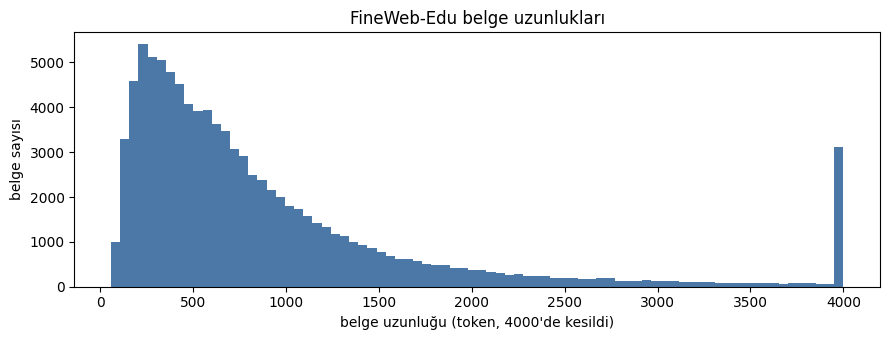

In [20]:
uz = np.array(edu_ozet["uzunluklar"])
display(pd.DataFrame([
    ("Shard sayısı", f"{len(edu_dosyalar)} (1 doğrulama + {len(edu_dosyalar) - 1} eğitim)"),
    ("Shard başına token", nokta(SHARD_TOKEN)),
    ("Eğitim token'ı", nokta((len(edu_dosyalar) - 1) * SHARD_TOKEN)),
    ("Doğrulama token'ı", nokta(SHARD_TOKEN)),
    ("Okunan belge", nokta(edu_ozet["belge"])),
    ("Belge başına token (ortalama / ortanca)", f"{uz.mean():.0f} / {np.median(uz):.0f}"),
    ("Hazırlama süresi", f"{edu_ozet['sure'] / 60:.1f} dk"),
    ("Diskte", f"{sum(os.path.getsize(d) for d in edu_dosyalar) / 2**20:.0f} MB"),
], columns=["", "Değer"]).style.hide(axis="index"))

fig, eksen = plt.subplots(figsize=(9, 3.5))
eksen.hist(np.clip(uz, 0, 4000), bins=80, color="#4c78a8")
eksen.set_xlabel("belge uzunluğu (token, 4000'de kesildi)")
eksen.set_ylabel("belge sayısı")
eksen.set_title("FineWeb-Edu belge uzunlukları")
plt.tight_layout()
plt.show()

Data loader Hafta 11'deki `DataLoaderLite` ile aynı mantıkta, tek fark artık bir token listesi değil bir shard listesi alması. Bir shard bitince sonrakini yüklüyor, hepsi bitince başa dönüyor. `reset()` ile baştan başlatılabiliyor, doğrulamada her seferinde aynı batch'leri ölçmek için bunu kullanacağım.

In [21]:
def shard_yukle(dosya):
    return torch.tensor(np.load(dosya).astype(np.int32), dtype=torch.long)


class ShardLoader:
    def __init__(self, dosyalar, B, T):
        self.dosyalar = dosyalar
        self.B, self.T = B, T
        self.reset()

    def reset(self):
        self.shard = 0
        self.tur = 0
        self.tokenler = shard_yukle(self.dosyalar[0])
        self.konum = 0

    def next_batch(self):
        B, T = self.B, self.T
        tampon = self.tokenler[self.konum : self.konum + B * T + 1]
        x = tampon[:-1].view(B, T)
        y = tampon[1:].view(B, T)
        self.konum += B * T
        if self.konum + B * T + 1 > len(self.tokenler):
            self.shard = (self.shard + 1) % len(self.dosyalar)
            if self.shard == 0:
                self.tur += 1
            self.tokenler = shard_yukle(self.dosyalar[self.shard])
            self.konum = 0
        return x, y


train_loader = ShardLoader(edu_dosyalar[1:], B, T)
val_loader = ShardLoader(edu_dosyalar[:1], B, T)
x, y = train_loader.next_batch()
assert bool((x.view(-1)[1:] == y.view(-1)[:-1]).all())
print(f"Eğitim shard'ları: {[os.path.basename(d) for d in train_loader.dosyalar]}")
print(f"Doğrulama shard'ı: {[os.path.basename(d) for d in val_loader.dosyalar]}")
print(f"x: {tuple(x.shape)}  |  ilk batch'teki <|endoftext|> sayısı (belge sınırı): {(x == EOT).sum().item()}")
print(f"\nx[0] ilk 300 karakter:\n{enc.decode(x[0].tolist())[:300]!r}")
train_loader.reset()

Eğitim shard'ları: ['edufineweb_train_000001.npy', 'edufineweb_train_000002.npy', 'edufineweb_train_000003.npy', 'edufineweb_train_000004.npy', 'edufineweb_train_000005.npy', 'edufineweb_train_000006.npy', 'edufineweb_train_000007.npy', 'edufineweb_train_000008.npy', 'edufineweb_train_000009.npy']
Doğrulama shard'ı: ['edufineweb_val_000000.npy']
x: (4, 1024)  |  ilk batch'teki <|endoftext|> sayısı (belge sınırı): 6

x[0] ilk 300 karakter:
' (1966) The Australian Pub, Melbourne University Press, Carlton.\n- 30 October 2014, In search of platforms 26 and 27: Central station’s mysterious underground world, The Daily Telegraph\n- C. Reinecke, 30 May 2010, , Griffith REVIEW Edition 28: Still the Lucky Country?\n- National Archives of Australi'


## Görev 2: Doğrulama loss'u ve örnekler *(Video 3:23:10 – 3:28:23)*

Eğitim sırasında belli aralıklarla doğrulama loss'unu ölç ve modelden kısa bir metin ürettir. Train ve val loss'u aynı grafikte çiz.

- `val_loss_olc`: doğrulama shard'ının başından 20 batch (20 × 4 × 1024 ≈ 82 bin token) alıp ortalama loss'u döndürüyor. Her ölçümde `reset()` çağırdığım için hep aynı token'lar ölçülüyor, böylece eğriler arasındaki fark modelden geliyor, veriden değil. Model bu token'ları eğitimde hiç görmüyor.
- `ornek_uret`: Hafta 10'daki top-k örnekleme döngüsü, bfloat16 ile. Tek fark: vocab 50.304'e yuvarlandığı için fazladan 47 token'ın logits'ini atıyorum, tokenizer'da karşılıkları yok.

İkisini önce rastgele başlatılmış modelde deniyorum. Loss ln(50257) ≈ 10.82 civarında, metin anlamsız olmalı.

In [22]:
@torch.no_grad()
def val_loss_olc(model, loader, adim=VAL_ADIM):
    onceki = model.training
    model.eval()
    loader.reset()
    toplam = 0.0
    for _ in range(adim):
        x, y = loader.next_batch()
        x, y = x.to(device), y.to(device)
        with torch.autocast(device_type=device_type, dtype=torch.bfloat16):
            _, loss = model(x, y)
        toplam += loss.item()
    model.train(onceki)
    return toplam / adim


@torch.no_grad()
def uret(model, idx, max_yeni, top_k=TOP_K, generator=None):
    onceki = model.training
    model.eval()
    for _ in range(max_yeni):
        idx_cond = idx[:, -model.config.block_size:]
        with torch.autocast(device_type=device_type, dtype=torch.bfloat16):
            logits, _ = model(idx_cond)
        olasilik = F.softmax(logits[:, -1, :enc.n_vocab].float(), dim=-1)
        top_olasilik, top_indeks = torch.topk(olasilik, top_k, dim=-1)
        secilen = torch.multinomial(top_olasilik, num_samples=1, generator=generator)
        idx = torch.cat((idx, torch.gather(top_indeks, -1, secilen)), dim=1)
    model.train(onceki)
    return idx


def ornek_uret(model, baslangic, adet=ORNEK_ADET, uzunluk=ORNEK_UZUNLUK):
    idx = torch.tensor(enc.encode(baslangic), dtype=torch.long, device=device).unsqueeze(0).repeat(adet, 1)
    g = torch.Generator(device=device)
    g.manual_seed(SEED)
    cikti = uret(model, idx, uzunluk, generator=g)
    return [enc.decode(c.tolist()) for c in cikti]


torch.manual_seed(SEED)
deneme_model = GPT(GPTConfig(vocab_size=50304, flash=True)).to(device)
print(f"Rastgele modelin doğrulama loss'u: {val_loss_olc(deneme_model, val_loader):.4f}  (ln(50257) = {math.log(50257):.4f})\n")
for metin in ornek_uret(deneme_model, "Hello, I'm a language model,", adet=2):
    print(repr(metin))
del deneme_model
torch.cuda.empty_cache()

Rastgele modelin doğrulama loss'u: 10.9553  (ln(50257) = 10.8249)



"Hello, I'm a language model, theatre unfolding precedence ABCleased borne surrounded Carnival fades Monster effectiveness xp neurot mitochond mitochondidental underway unlock fingerprintentsiko nem Recover Effective effectivenessulaimated heav enter ElephantCV Prediction"
"Hello, I'm a language model,used clothing senate disproportionate protesteragin rodents Elephant upgr� Effective prim Presleased philosophical preempt Pul uncertaintyHTTP dismal Cinem patriAPD subs Monster urge BioScene breastervesmire mandatory"


## Görev 3: Modelini eğit *(Video 3:28:23 – 3:43:05)*

Hafta 11'de hızlandırdığın GPT-2'yi donanımına göre belli bir süre eğit, örneğin Colab'da bir saat. Kaç token gördüğünü, saniyede kaç token işlediğini ve son loss'u yaz. Eğitim ilerledikçe ürettiği metin nasıl değişiyor?

### HellaSwag'i eğitim sırasında da ölçmek

Videoda olduğu gibi HellaSwag'i (Görev 4) eğitim sırasında da izlemek istiyorum, bu yüzden değerlendirme kodunu burada yazıyorum.

HellaSwag'de her örnekte bir bağlam ve dört olası devam var, biri doğru. Küçük bir dil modeli çoktan seçmeli soruyu "A, B, C, D" diye cevaplayamaz, o yüzden Karpathy'nin yaptığı gibi her seçeneği bağlamın arkasına ekleyip dört satırlık bir batch yapıyorum. Model her satırda devam kısmındaki token'lara ne kadar olasılık veriyor, ona bakıyorum: devam token'larının ortalama loss'u en düşük olan seçenek modelin cevabı. Bağlam token'ları maskeleniyor, satırlar farklı uzunlukta olduğu için sonları 0 ile dolduruluyor ve maskede 0 oluyor. İki ölçü raporluyorum:

- **acc**: devam token'larının toplam loss'u en düşük olan seçenek. Uzun seçenekler daha çok token tuttuğu için cezalanıyor.
- **acc_norm**: ortalama loss, yani uzunluğa göre normalize edilmiş hali. Karpathy grafikte bunu kullanıyor.

Veriyi Karpathy'nin kullandığı GitHub adresinden indiremedim (depo erişime kapalı), aynı doğrulama setini Hugging Face'teki `Rowan/hellaswag` kopyasından okuyorum: 10.042 örnek, alanlar aynı. Eğitim sırasında doğrulama setinin ilk 1000 örneğine, eğitim bitince 10.042 örneğin tamamına bakıyorum.

In [23]:
def hellaswag_yukle():
    veri = load_dataset("Rowan/hellaswag", split="validation")
    return [dict(ctx=o["ctx"], endings=o["endings"], label=int(o["label"])) for o in veri]


def hellaswag_hazirla(ornek):
    baglam = enc.encode(ornek["ctx"])
    satirlar, maskeler = [], []
    for son in ornek["endings"]:
        devam = enc.encode(" " + son)
        satirlar.append(baglam + devam)
        maskeler.append([0] * len(baglam) + [1] * len(devam))
    uzun = max(len(s) for s in satirlar)
    tokenler = torch.zeros((4, uzun), dtype=torch.long)
    maske = torch.zeros((4, uzun), dtype=torch.long)
    for i, (s, m) in enumerate(zip(satirlar, maskeler)):
        tokenler[i, :len(s)] = torch.tensor(s)
        maske[i, :len(m)] = torch.tensor(m)
    return tokenler, maske, ornek["label"]


@torch.no_grad()
def hellaswag_olc(model, ornekler):
    onceki = model.training
    model.eval()
    dogru = dogru_norm = 0
    for ornek in ornekler:
        tokenler, maske, etiket = hellaswag_hazirla(ornek)
        tokenler, maske = tokenler.to(device), maske.to(device)
        with torch.autocast(device_type=device_type, dtype=torch.bfloat16):
            logits, _ = model(tokenler)
        kayip = F.cross_entropy(
            logits[:, :-1, :].float().reshape(-1, logits.size(-1)), tokenler[:, 1:].reshape(-1), reduction="none"
        ).view(4, -1)
        m = maske[:, 1:]
        toplam = (kayip * m).sum(dim=1)
        ortalama = toplam / m.sum(dim=1)
        dogru += int(toplam.argmin().item() == etiket)
        dogru_norm += int(ortalama.argmin().item() == etiket)
    model.train(onceki)
    return dict(n=len(ornekler), dogru=dogru, dogru_norm=dogru_norm, acc=dogru / len(ornekler), acc_norm=dogru_norm / len(ornekler))


hs_ornekler = hellaswag_yukle()
print(f"HellaSwag doğrulama seti: {nokta(len(hs_ornekler))} örnek")
ornek = hs_ornekler[0]
print(f"\nBağlam: {ornek['ctx']!r}")
for i, son in enumerate(ornek["endings"]):
    print(f"  {'*' if i == ornek['label'] else ' '} {i}: {son!r}")
tokenler, maske, _ = hellaswag_hazirla(ornek)
print(f"\nBatch: {tuple(tokenler.shape)}  |  her satırdaki devam token'ı: {maske.sum(dim=1).tolist()}")

HellaSwag doğrulama seti: 10.042 örnek

Bağlam: 'A man is sitting on a roof. he'
    0: 'is using wrap to wrap a pair of skis.'
    1: 'is ripping level tiles off.'
    2: "is holding a rubik's cube."
  * 3: 'starts pulling up roofing on a roof.'

Batch: (4, 20)  |  her satırdaki devam token'ı: [11, 6, 8, 9]


### Eğitim döngüsü

Hafta 11 Görev 3'teki döngünün aynısı, üstüne belli aralıklarla doğrulama loss'u, HellaSwag ve örnek üretme ekledim. Değerlendirmeleri derlenmemiş modelle yapıyorum: torch.compile'ın modeli ile ham model aynı parametreleri paylaşıyor, ama HellaSwag'de her örneğin uzunluğu farklı olduğu için derlenmiş model her şekilde yeniden derlenirdi.

Ayarlar:

- Toplam batch 2^16 = 65.536 token (16 × 4 × 1024). GPT-3'ün 0.5M'luk batch'i bir saatte yalnızca ~160 adım verirdi, 65 bin token'la ~1.300 adım oluyor. Learning rate yine 6e-4, 6e-5'e iniyor.
- `max_adim` sabit değil: Hafta 11 Görev 3'te ölçtüğüm token/sn ile 60 dakikaya kaç adım sığacağını hesaplıyorum. Cosine schedule'un ne zaman biteceğini önceden bilmesi gerekiyor. Warmup ilk %5.
- Her 100 adımda doğrulama loss'u, her 250 adımda HellaSwag (ilk 1000 örnek) ve örnek metin.

In [24]:
def egit(model, train_loader, val_loader, max_adim, warmup, toplam_batch, baslangic, deger_her, ornek_her, hs_her=None, hs_ornekler=None):
    grad_accum = toplam_batch // (train_loader.B * train_loader.T)
    optimizer = model.configure_optimizers(WEIGHT_DECAY, MAX_LR, device_type)
    calisan = torch.compile(model) if derleme_var else model
    log = dict(train=[], val=[], hs=[], ornek=[])
    egitim_suresi = 0.0
    t_bas = time.time()

    def degerlendir(adim):
        if adim % deger_her == 0 or adim == max_adim:
            v = val_loss_olc(model, val_loader)
            log["val"].append((adim, v))
            print(f"--- adım {adim:5d} | val loss {v:.4f}")
        if hs_ornekler is not None and (adim % hs_her == 0 or adim == max_adim):
            hs = hellaswag_olc(model, hs_ornekler)
            log["hs"].append((adim, hs["acc_norm"]))
            print(f"--- adım {adim:5d} | HellaSwag acc_norm {hs['dogru_norm']}/{hs['n']} = {hs['acc_norm']:.4f}")
        if adim % ornek_her == 0 or adim == max_adim:
            metinler = ornek_uret(model, baslangic)
            log["ornek"].append((adim, metinler))
            for metin in metinler:
                print(f"    {metin!r}")

    for adim in range(max_adim):
        degerlendir(adim)
        t0 = time.time()
        optimizer.zero_grad()
        loss_toplam = 0.0
        for _ in range(grad_accum):
            x, y = train_loader.next_batch()
            x, y = x.to(device), y.to(device)
            with torch.autocast(device_type=device_type, dtype=torch.bfloat16):
                _, loss = calisan(x, y)
            loss = loss / grad_accum
            loss_toplam += loss.detach()
            loss.backward()
        norm = torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        lr = lr_hesapla(adim, MAX_LR, MIN_LR, warmup, max_adim)
        for grup in optimizer.param_groups:
            grup["lr"] = lr
        optimizer.step()
        torch.cuda.synchronize()
        dt = time.time() - t0
        egitim_suresi += dt
        log["train"].append(dict(adim=adim, loss=loss_toplam.item(), lr=lr, norm=norm.item(), dt=dt, tok_s=toplam_batch / dt))
        if adim % 25 == 0 or adim == max_adim - 1:
            print(f"adım {adim:5d} | loss {loss_toplam.item():.4f} | lr {lr:.2e} | norm {norm.item():.3f} | {dt * 1000:.0f} ms | {toplam_batch / dt:.0f} token/sn")
    degerlendir(max_adim)
    log["train"] = pd.DataFrame(log["train"])
    log["egitim_suresi"] = egitim_suresi
    log["toplam_sure"] = time.time() - t_bas
    del optimizer, calisan
    gc.collect()
    torch.cuda.empty_cache()
    torch._dynamo.reset()
    return log


MAX_ADIM = int(EGITIM_DAKIKA * 60 * h11_hiz / TOPLAM_BATCH)
WARMUP = max(1, MAX_ADIM // 20)
print(f"Ölçülen hız {h11_hiz:.0f} token/sn -> {EGITIM_DAKIKA} dakikada {MAX_ADIM} adım x {nokta(TOPLAM_BATCH)} token = {nokta(MAX_ADIM * TOPLAM_BATCH)} token")
print(f"warmup {WARMUP} adım  |  grad_accum {TOPLAM_BATCH // (B * T)}  |  eğitim verisi {nokta((len(edu_dosyalar) - 1) * SHARD_TOKEN)} token\n")

torch.manual_seed(SEED)
model = GPT(GPTConfig(vocab_size=50304, flash=True)).to(device)
train_loader.reset()
log = egit(model, train_loader, val_loader, MAX_ADIM, WARMUP, TOPLAM_BATCH, "Hello, I'm a language model,",
           DEGER_HER, ORNEK_HER, HS_HER, hs_ornekler[:HS_ARA_ORNEK])

Ölçülen hız 23246 token/sn -> 60 dakikada 1276 adım x 65.536 token = 83.623.936 token
warmup 63 adım  |  grad_accum 16  |  eğitim verisi 90.000.000 token



--- adım     0 | val loss 10.9553


--- adım     0 | HellaSwag acc_norm 236/1000 = 0.2360


    "Hello, I'm a language model, theatre minor tactical LI TIBurnocation Twiceesthesia leanedBurn』 fades� ≡ weightasonrytier malice recommendation paramWritmirecollaruff Roose signedgr postpone368368 nowhere"
    "Hello, I'm a language model,745 geographic protester forged rodentscollar Chandra surroundedfp Chandra Effective caught submitting submitting Effective favouritesasonrycollarfp exponentially nat ChinatownThread 65 FPS Lauderdaleulateness draconbyssRevolution caught"
    "Hello, I'm a language model,post surrounded restraints toughestReillyda damning judged mother flaw Dol OpenGLashing1992icts Monster occasional counter toughest toughestuninun Lovingmore Motorola Motorolameal externalToEVA vibe regulator glimpse emerging"
    "Hello, I'm a language model, forged Cinemdada802802 rodents malice TI clothingttyanka relentless rodents980Sum Kerala VOLblind Deckerorio Yang Berserker Garrettushi Friend river toughestkees Portabledeen precarious"


adım     0 | loss 10.9506 | lr 9.52e-06 | norm 16.013 | 3668 ms | 17866 token/sn


adım    25 | loss 7.8430 | lr 2.48e-04 | norm 1.236 | 3005 ms | 21808 token/sn


... (70 outputs left out)

adım  1275 | loss 4.9361 | lr 6.00e-05 | norm 0.461 | 2704 ms | 24241 token/sn


--- adım  1276 | val loss 4.8142


--- adım  1276 | HellaSwag acc_norm 275/1000 = 0.2750


    "Hello, I'm a language model, and I can read my own teaching goals here.\nI are only able to tell a “trees,” they can be used for the �"
    "Hello, I'm a language model, i.e., with a simple language definition\n1. This is not uncommon, but it isn’t really good for you to think about the world"
    "Hello, I'm a language model, I’re now sure I’ve had lots of problems, you’ve got to have an experience of the concept of how it came in"
    "Hello, I'm a language model, I just had a lot about the world. If the I was the whole, that did I get my computer software that I would still want to learn English."


,Değer
Adım,1.276
Görülen token,83.623.936
Eğitim verisinin üzerinden geçiş,0.93 tur
Saf eğitim süresi,72.7 dk
Değerlendirmelerle toplam süre,74.5 dk
Ortalama hız (derleme dahil),19.160 token/sn
Ortanca adım hızı,21.319 token/sn
Ortanca / en uzun adım süresi,3.07 / 22.56 sn
İlk adım (torch.compile dahil),3.7 sn
Son train loss (son 20 adımın ortalaması),4.7564


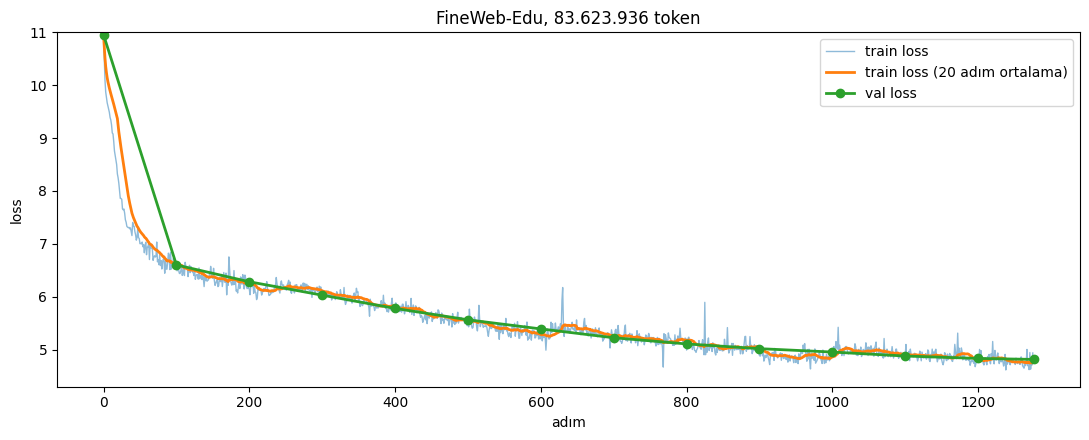

In [25]:
en_log = log["train"]
gorulen = MAX_ADIM * TOPLAM_BATCH
hiz = gorulen / log["egitim_suresi"]
display(pd.DataFrame([
    ("Adım", nokta(MAX_ADIM)),
    ("Görülen token", nokta(gorulen)),
    ("Eğitim verisinin üzerinden geçiş", f"{gorulen / ((len(edu_dosyalar) - 1) * SHARD_TOKEN):.2f} tur"),
    ("Saf eğitim süresi", f"{log['egitim_suresi'] / 60:.1f} dk"),
    ("Değerlendirmelerle toplam süre", f"{log['toplam_sure'] / 60:.1f} dk"),
    ("Ortalama hız (derleme dahil)", f"{nokta(round(hiz))} token/sn"),
    ("Ortanca adım hızı", f"{nokta(round(en_log['tok_s'].iloc[5:].median()))} token/sn"),
    ("Ortanca / en uzun adım süresi", f"{en_log['dt'].iloc[5:].median():.2f} / {en_log['dt'].iloc[1:].max():.2f} sn"),
    ("İlk adım (torch.compile dahil)", f"{en_log['dt'].iloc[0]:.1f} sn"),
    ("Son train loss (son 20 adımın ortalaması)", f"{en_log['loss'].iloc[-20:].mean():.4f}"),
    ("Son val loss", f"{log['val'][-1][1]:.4f}"),
], columns=["", "Değer"]).style.hide(axis="index"))

val_adim, val_deger = zip(*log["val"])
fig, eksen = plt.subplots(figsize=(11, 4.5))
eksen.plot(en_log["adim"], en_log["loss"], linewidth=1, alpha=0.5, label="train loss")
eksen.plot(en_log["adim"], en_log["loss"].rolling(20, min_periods=1).mean(), linewidth=2, label="train loss (20 adım ortalama)")
eksen.plot(val_adim, val_deger, marker="o", linewidth=2, label="val loss")
eksen.set_xlabel("adım")
eksen.set_ylabel("loss")
eksen.set_ylim(top=min(11, max(val_deger) + 0.3))
eksen.set_title(f"FineWeb-Edu, {nokta(gorulen)} token")
eksen.legend()
plt.tight_layout()
plt.show()

**Cevap: Kaç token gördü, saniyede kaç token işledi, son loss ne?**

- **1.276 adım × 65.536 = 83.623.936 token.** Eğitim verisinin %93'ü, yani model hiçbir belgeyi iki kez görmedi.
- **Hız:** ortalama **19.160 token/sn**, ortanca adımda 21.319 token/sn. Adım süresinin ortancası 3.07 sn.
- **Son train loss 4.756** (son 20 adımın ortalaması), **son val loss 4.814.**

Eğitimi 60 dakikaya göre planlamıştım (Hafta 11'de ölçülen 23.246 token/sn ile) ama saf eğitim **72.7 dakika** sürdü. Hız eğitim boyunca dalgalandı: bazı aralıklarda adım başına 24 bin token/sn (2.7 sn), bazı aralıklarda 17 bin token/sn (3.9 sn), en uzun adım 22.6 sn. Nedenini ölçmedim. GPU belleği 8 GB'ın sınırındaydı (nvidia-smi'de ~7.7 GB), Windows da sınır aşılınca sistem RAM'ini kullanıyor. Benim tahminim yavaşlamanın bundan geldiği. Isıdan olduğunu sanmıyorum, çünkü yavaş aralıklar laptopun fanları tam devirdeyken (GPU ~70°C) de oldu.

Train ve val loss eğitimin sonuna kadar neredeyse üst üste gitti (4.76 ile 4.81). Model veriyi bir turdan az gördüğü için ezberleme yok, val loss'taki her düşüş gerçek öğrenme. Val loss eğrisi henüz düzleşmedi, daha uzun eğitim daha iyi sonuç verirdi. OpenAI GPT-2 aynı doğrulama token'larında 3.264 alıyor, karşılaştırma Görev 4'te.

### Üretilen metin eğitim boyunca nasıl değişti?

Her ölçümde aynı başlangıç cümlesiyle ve aynı seed'le dört örnek ürettim. Aşağıda her ölçümün ilk iki örneği var.

In [26]:
for adim, metinler in log["ornek"]:
    print(f"=== adım {adim} ===")
    for metin in metinler[:2]:
        print(f"  {metin!r}")
    print()

=== adım 0 ===
  "Hello, I'm a language model, theatre minor tactical LI TIBurnocation Twiceesthesia leanedBurn』 fades� ≡ weightasonrytier malice recommendation paramWritmirecollaruff Roose signedgr postpone368368 nowhere"
  "Hello, I'm a language model,745 geographic protester forged rodentscollar Chandra surroundedfp Chandra Effective caught submitting submitting Effective favouritesasonrycollarfp exponentially nat ChinatownThread 65 FPS Lauderdaleulateness draconbyssRevolution caught"

=== adım 250 ===
  "Hello, I'm a language model, because the book on to the world could lead to get the history may be taken to find through God, however. In the book, and the Church, and"
  "Hello, I'm a language model, when the other. And, by the work out, that this is that there is.\n” when I“I” “”"

=== adım 500 ===
  "Hello, I'm a language model, but I can see that I are made into the process.\nThese features and physics in what could have made from a mathematical process.\nA process is a"
  "Hel

**Cevap: Eğitim ilerledikçe üretilen metin nasıl değişiyor?**

- **Adım 0:** Rastgele token yığını ("theatre minor tactical LI TIBurnocation..."), kelime parçaları ve sayılar. Model her token'ı neredeyse eşit olasılıkla seçiyor.
- **Adım 250 (16M token):** Artık İngilizce kelimeler ve noktalama var. Kısa ifadeler kuruluyor ("In the book, and the Church") ama cümle yok, "the", "and" ve virgül çok tekrarlanıyor.
- **Adım 500 (33M token):** Cümlelerin iskeleti oturmaya başladı ("The goal of a list", "A process is a"). Konular FineWeb-Edu'ya benziyor: process, physics, project, teacher.
- **Adım 750–1000:** Model başlangıçtaki "language" kelimesini yakalayıp konu olarak sürdürüyor ("I can learn to think about if you are a language"). Birinci tekil şahısla daha uzun cümleler kuruyor, ama cümleler anlamca birbirine bağlanmıyor.
- **Son (84M token):** Liste yapısı ("1. This is not uncommon, but it isn't really good for you...") ve okul, öğretmen, öğrenmek temaları sürekli tekrar ediyor. Veri eğitim siteleri olduğu için bu beklenen bir şey. 1250. adımda `<|endoftext|>` da üretti, yani model belgelerin nerede bittiğini de öğrenmiş. Dilbilgisi hataları hâlâ var ("I are only able", "I're now sure").

Kısacası önce token istatistiği, sonra kelimeler, sonra cümle yapısı geldi. Anlam bütünlüğü henüz gelmedi. Aynı başlangıçla OpenAI GPT-2'nin ürettiği metin (Görev 4'te) çok daha akıcı.

## Görev 4: HellaSwag'de ölç *(Video 3:28:23 – 3:56:21)*

HellaSwag'i önce kendi modelinde, sonra OpenAI'ın GPT-2 ağırlıklarında koş. Rastgele tahmin yüzde 25 doğru bulur. Senin modelin ne kadar buluyor, OpenAI'ın modelinden ne kadar uzakta? Aradaki farkın nereden geldiğini kendi cümlelerinle yaz.

OpenAI'ın ağırlıklarını Hafta 10'daki gibi kendi `GPT` sınıfıma yüklüyorum (dört ağırlık transpoze), aynı `hellaswag_olc` fonksiyonuyla ölçüyorum. İki modeli doğrulama setinin **10042 örneğinin** hepsinde ölçtüm. Ayrıca GPT-2'yi benim FineWeb-Edu doğrulama shard'ımda da ölçüyorum, aynı tokenizer'ı kullandıkları için val loss'ları doğrudan karşılaştırılabilir.

In [27]:
TRANSPOZ = ("attn.c_attn.weight", "attn.c_proj.weight", "mlp.c_fc.weight", "mlp.c_proj.weight")


def agirliklari_yukle(model, hf_state):
    hf_anahtarlar = [k for k in hf_state if not k.endswith((".attn.bias", ".attn.masked_bias"))]
    state = model.state_dict()
    assert sorted(hf_anahtarlar) == sorted(state.keys()), "Anahtar adları eşleşmiyor"
    with torch.no_grad():
        for k in hf_anahtarlar:
            if k.endswith(TRANSPOZ):
                assert hf_state[k].shape[::-1] == state[k].shape
                state[k].copy_(hf_state[k].t())
            else:
                assert hf_state[k].shape == state[k].shape
                state[k].copy_(hf_state[k])
    return model


hf_model = GPT2LMHeadModel.from_pretrained("gpt2")
gpt2_model = agirliklari_yukle(GPT(GPTConfig(flash=True)), hf_model.state_dict()).to(device)
del hf_model

t0 = time.time()
hs_benim = hellaswag_olc(model, hs_ornekler[:HS_SON_ORNEK])
print(f"Benim modelim : {hs_benim['dogru']}/{hs_benim['n']} (acc), {hs_benim['dogru_norm']}/{hs_benim['n']} (acc_norm)  |  {time.time() - t0:.0f} sn")
t0 = time.time()
hs_gpt2 = hellaswag_olc(gpt2_model, hs_ornekler[:HS_SON_ORNEK])
print(f"OpenAI GPT-2  : {hs_gpt2['dogru']}/{hs_gpt2['n']} (acc), {hs_gpt2['dogru_norm']}/{hs_gpt2['n']} (acc_norm)  |  {time.time() - t0:.0f} sn")
hs_gpt2_ara = hellaswag_olc(gpt2_model, hs_ornekler[:HS_ARA_ORNEK])
val_gpt2 = val_loss_olc(gpt2_model, val_loader)
val_benim = val_loss_olc(model, val_loader)

hata = (0.25 * 0.75 / hs_benim["n"]) ** 0.5
display(pd.DataFrame([
    ("Rastgele tahmin", "-", "-", "%25.00", "%25.00", "-"),
    ("Benim modelim", nokta(gorulen), f"{hs_benim['dogru_norm']}", f"%{hs_benim['acc'] * 100:.2f}", f"%{hs_benim['acc_norm'] * 100:.2f}", f"{val_benim:.4f}"),
    ("OpenAI GPT-2 (124M)", "açıklanmadı (WebText, ~40 GB)", f"{hs_gpt2['dogru_norm']}", f"%{hs_gpt2['acc'] * 100:.2f}", f"%{hs_gpt2['acc_norm'] * 100:.2f}", f"{val_gpt2:.4f}"),
], columns=["Model", "Eğitim token'ı", f"Doğru (acc_norm, {hs_benim['n']} örnek)", "acc", "acc_norm", "FineWeb-Edu val loss"]).style.hide(axis="index"))
print(f"{hs_benim['n']} örnekte bir doğruluk ölçümünün standart hatası yaklaşık ±%{hata * 100:.2f}")

Loading weights:   0%|          | 0/148 [00:00<?, ?it/s]

Loading weights:  23%|██▎       | 34/148 [00:00<00:00, 338.36it/s]

Loading weights:  47%|████▋     | 69/148 [00:00<00:00, 344.93it/s]

Loading weights:  70%|███████   | 104/148 [00:00<00:00, 256.53it/s]

Loading weights: 100%|██████████| 148/148 [00:00<00:00, 388.04it/s]

Benim modelim : 2601/10042 (acc), 2436/10042 (acc_norm)  |  123 sn


OpenAI GPT-2  : 2873/10042 (acc), 2985/10042 (acc_norm)  |  128 sn


Model,Eğitim token'ı,"Doğru (acc_norm, 10042 örnek)",acc,acc_norm,FineWeb-Edu val loss
Rastgele tahmin,-,-,%25.00,%25.00,-
Benim modelim,83.623.936,2436,%25.90,%24.26,4.8142
OpenAI GPT-2 (124M),"açıklanmadı (WebText, ~40 GB)",2985,%28.61,%29.73,3.2641


10042 örnekte bir doğruluk ölçümünün standart hatası yaklaşık ±%0.43


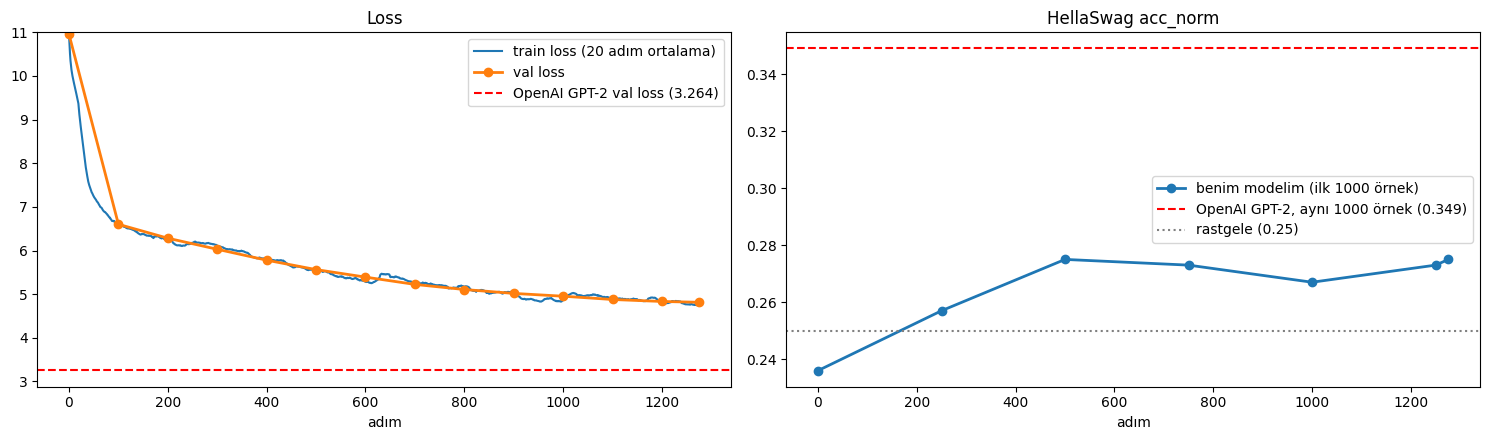

Aynı başlangıç cümlesiyle OpenAI GPT-2:


  'Hello, I\'m a language model, and I want to talk about things one at a time.\n\n"But I have several examples, such as:\n\nThe language model needs to be'
  'Hello, I\'m a language model, just like you."\n\n"Yeah."\n\n"Then I want that back."\n\n"Maybe it\'s a good idea to call it the C'

Benim modelim (eğitim sonu):
  "Hello, I'm a language model, and I can read my own teaching goals here.\nI are only able to tell a “trees,” they can be used for the �"
  "Hello, I'm a language model, i.e., with a simple language definition\n1. This is not uncommon, but it isn’t really good for you to think about the world"


In [28]:
hs_adim, hs_deger = zip(*log["hs"])
fig, eksenler = plt.subplots(1, 2, figsize=(15, 4.5))
eksenler[0].plot(en_log["adim"], en_log["loss"].rolling(20, min_periods=1).mean(), linewidth=1.5, label="train loss (20 adım ortalama)")
eksenler[0].plot(val_adim, val_deger, marker="o", linewidth=2, label="val loss")
eksenler[0].axhline(val_gpt2, color="red", linestyle="--", label=f"OpenAI GPT-2 val loss ({val_gpt2:.3f})")
eksenler[0].set_ylim(top=min(11, max(val_deger) + 0.3))
eksenler[0].set_title("Loss")
eksenler[0].set_xlabel("adım")
eksenler[0].legend()
eksenler[1].plot(hs_adim, hs_deger, marker="o", linewidth=2, label=f"benim modelim (ilk {HS_ARA_ORNEK} örnek)")
eksenler[1].axhline(hs_gpt2_ara["acc_norm"], color="red", linestyle="--", label=f"OpenAI GPT-2, aynı {HS_ARA_ORNEK} örnek ({hs_gpt2_ara['acc_norm']:.3f})")
eksenler[1].axhline(0.25, color="gray", linestyle=":", label="rastgele (0.25)")
eksenler[1].set_title("HellaSwag acc_norm")
eksenler[1].set_xlabel("adım")
eksenler[1].legend()
plt.tight_layout()
plt.show()

print("Aynı başlangıç cümlesiyle OpenAI GPT-2:")
for metin in ornek_uret(gpt2_model, "Hello, I'm a language model,", adet=2):
    print(f"  {metin!r}")
print("\nBenim modelim (eğitim sonu):")
for metin in log["ornek"][-1][1][:2]:
    print(f"  {metin!r}")

**Cevap: Modelim HellaSwag'de ne kadar buluyor, OpenAI'ın modelinden ne kadar uzakta?**

10.042 örneğin tamamında:

| Model | Doğru (acc_norm) | acc_norm | acc | Val loss |
|---|---|---|---|---|
| Rastgele | – | %25.00 | %25.00 | – |
| Benim modelim (84M token, 1 saat) | 2.436 | **%24.26** | %25.90 | 4.814 |
| OpenAI GPT-2 (124M) | 2.985 | **%29.73** | %28.61 | 3.264 |

OpenAI GPT-2 için bulduğum %29.73, Karpathy'nin `hellaswag.py`'sinde yazan 0.2955'e çok yakın. Ufak fark bfloat16 kullanmamdan olabilir. Değerlendirme kodunun doğru çalıştığını buradan anlıyorum.

**Benim modelim HellaSwag'de rastgeleden ayırt edilemiyor.** acc_norm %24.26, acc %25.90. 10.042 örnekte standart hata ±%0.43, iki sayı da 25'in iki standart hata yakınında. OpenAI GPT-2'nin **5.5 puan gerisindeyim.** Val loss'ta fark daha belirgin: 4.81'e 3.26.

Eğitim sırasındaki eğri (sağdaki grafik) daha iyimser görünüyor: ilk 1000 örnekte 0.236'dan 0.275'e çıktı. Ama aynı 1000 örnekte GPT-2 de 0.349 alıyor, tüm sette ise 0.297. Yani ilk 1000 örnek setin geri kalanından daha kolay, ara ölçümler de 1000 örnekte ±1.4 puanlık gürültü taşıyor. Asıl sonuç tam setteki sonuç.

**Fark nereden geliyor?**

1. **Veri miktarı.** Ana sebep bu. Ben 84 milyon token gösterdim. Karpathy aynı mimariyle aynı veride (FineWeb-Edu) GPT-2'yi geçmek için 10 milyar token kullandı, yani benimkinin 120 katı. GPT-3 makalesindeki 124M model 300 milyar token görmüş. OpenAI GPT-2'nin kaç token'la eğitildiğini açıklamadı ama WebText 40 GB metin, bu kabaca 10 milyar token ediyor.
2. **Hesap gücü.** Karpathy 8 tane A100'le saniyede yaklaşık 1.5 milyon token işledi, ben bir laptop GPU'suyla 19 bin. Aynı sürede ~80 kat daha az token.
3. **HellaSwag sağduyu istiyor.** Doğru seçeneği bulmak için modelin dünyadaki olayların nasıl ilerlediğini bilmesi lazım. Benim modelim henüz dilbilgisini oturtmaya çalışıyor (Görev 3'teki örnekler). Videodaki eğride de HellaSwag ilk adımlarda 0.25 civarında kalıyor, ancak çok daha fazla token sonra yükseliyor.
4. **Mimari ve kod değil.** Model ikisinde de aynı 124M'lik GPT-2. OpenAI'ın ağırlıklarını aynı kodla yükleyince %29.7 çıkıyor. Fark tamamen ağırlıklardan, yani ne kadar ve ne ile eğitildiklerinden geliyor. Veri türü de sorun değil, çünkü Karpathy aynı FineWeb-Edu ile GPT-2'yi geçti.

## Görev 5 (ek): Türkçe GPT-2 *(Videoda yok)*

Aynı modeli Türkçe metinle eğit ve ürettiği Türkçe metinden örnek ver. HellaSwag İngilizce olduğu için Türkçe modeli nasıl ölçerdin?

Hafta 11'deki roman 124M'lik bir model için çok küçüktü (birkaç tur sonra ezberlemeye başladı). Burada FineWeb-Edu'nun yapıldığı ekibin çok dilli veri seti FineWeb-2'nin Türkçe kısmını (`tur_Latn`) kullandım. Görev 1'deki `shard_yaz` fonksiyonunu olduğu gibi kullanıyorum, sadece kaynak değişiyor: 4 shard (10M doğrulama, 30M eğitim token'ı). Tokenizer yine GPT-2'nin, böylece model kodu, loader ve eğitim döngüsü hiç değişmiyor. Bedeli şu: Türkçe GPT-2 tokenizer'ında çok daha fazla token tutuyor, aynı token sayısında daha az metin görülüyor (Hafta 10'da aynı cümle için 2.87 kat bulmuştum).

Eğitim 15 dakika, ayarlar İngilizce eğitimle aynı.

In [29]:
tr_dosyalar, tr_ozet = shard_yaz(VERI_TR, "fineweb2_tr", "HuggingFaceFW/fineweb-2", "tur_Latn", TR_SHARD)
tr_train_loader = ShardLoader(tr_dosyalar[1:], B, T)
tr_val_loader = ShardLoader(tr_dosyalar[:1], B, T)

x, _ = tr_train_loader.next_batch()
metin = enc.decode(x[0].tolist())
print(f"Belge sayısı: {nokta(tr_ozet['belge'])}  |  belge başına ortalama {np.mean(tr_ozet['uzunluklar']):.0f} token")
print(f"Örnek batch'te byte / token: Türkçe {len(metin.encode('utf-8')) / T:.2f}", end="")
x, _ = train_loader.next_batch()
print(f", İngilizce (FineWeb-Edu) {len(enc.decode(x[0].tolist()).encode('utf-8')) / T:.2f}")
print(f"\nTürkçe batch'in ilk 300 karakteri:\n{metin[:300]!r}")
tr_train_loader.reset()
train_loader.reset()

  fineweb2_tr_val_000000.npy yazıldı  |  4.591 belge  |  4 sn


  fineweb2_tr_train_000001.npy yazıldı  |  8.861 belge  |  6 sn


  fineweb2_tr_train_000002.npy yazıldı  |  13.683 belge  |  7 sn


  fineweb2_tr_train_000003.npy yazıldı  |  18.345 belge  |  8 sn
Belge sayısı: 18.345  |  belge başına ortalama 2180 token
Örnek batch'te byte / token: Türkçe 2.01, İngilizce (FineWeb-Edu) 4.64

Türkçe batch'in ilk 300 karakteri:
'unu ifade ederek, ‘Yeni bir dünya kuruluyor.ve bu dünyada Türkiye çok önemli bir aktör ve daha genç beyinlerin dünyası.’.\nENTİM A.Ş. Yönetіm Kurulu Başkanı Enis Timuçin, yeni bir dünya kurulduğunu ve bu dünyada Türkiye’nin çok önemli bir aktör olduğunu ifadе еdеrеk, “Yenі bir dünya kuruluyor. ve bu '


In [30]:
model = model.cpu()
gpt2_model = gpt2_model.cpu()
gc.collect()
torch.cuda.empty_cache()
print(f"Türkçe eğitimden önce GPU'da ayrılmış bellek: {torch.cuda.memory_allocated() / 2**30:.2f} GB")

TR_MAX_ADIM = int(TR_EGITIM_DAKIKA * 60 * h11_hiz / TOPLAM_BATCH)
TR_WARMUP = max(1, TR_MAX_ADIM // 20)
print(f"{TR_EGITIM_DAKIKA} dakika -> {TR_MAX_ADIM} adım x {nokta(TOPLAM_BATCH)} token = {nokta(TR_MAX_ADIM * TOPLAM_BATCH)} token, warmup {TR_WARMUP}\n")

torch.manual_seed(SEED)
tr_model = GPT(GPTConfig(vocab_size=50304, flash=True)).to(device)
tr_log = egit(tr_model, tr_train_loader, tr_val_loader, TR_MAX_ADIM, TR_WARMUP, TOPLAM_BATCH, "Türkiye'nin en güzel şehirlerinden biri",
              TR_DEGER_HER_H12, TR_ORNEK_HER)

Türkçe eğitimden önce GPU'da ayrılmış bellek: 1.40 GB
15 dakika -> 319 adım x 65.536 token = 20.905.984 token, warmup 15



--- adım     0 | val loss 10.9906


    "Türkiye'nin en güzel şehirlerinden biri)--abilities GoatliteWrit fortun SDL057Uk Canadian Learnsatten welcome Filipino uncertaintybumRon sample++++++++teness improper HOU Masonicgif vibe rece trail)-- 243awareness Cou Cou"
    "Türkiye'nin en güzel şehirlerinden birisell CBS bump ineligible Yus�becleftshallcan ValueELL Dota grad honorable professionally Cyberroad judged CENTtrack People consultants segregated 220 nowherehwhedon relentlessfuture goalCHR"
    "Türkiye'nin en güzel şehirlerinden biri degradationocalyodor Haley airstrike Dionuchaucha uncertaintyricestellariles mund proponent tablespoonsrices war� VII VIIampoo contributors Falcon provincialwewe lightsaber Face Dreamsrint VII Izan"
    "Türkiye'nin en güzel şehirlerinden biriDOOpening Sche sample Dietaryrint Glow guidelines retali gripped peasantsriftstatement slash JD cookie Strawberry neutralityScenemire overlookedDO GRE contributors typed altitudesell Feel contributors chemicals ✔iles"


adım     0 | loss 11.0067 | lr 4.00e-05 | norm 18.354 | 3447 ms | 19014 token/sn


adım    25 | loss 5.8410 | lr 5.99e-04 | norm 0.859 | 2692 ms | 24344 token/sn


--- adım    50 | val loss 5.3376


... (17 outputs left out)

    "Türkiye'nin en güzel şehirlerinden biri yüyıkçir (mır.\nAnadın, habek, hareketlerine göz böl"
    "Türkiye'nin en güzel şehirlerinden biri sünısı ile ulaşe başim, insanı kaldında, arasınınüy"
    "Türkiye'nin en güzel şehirlerinden biri öldurlarıylaştürıyla zafer” yapmiyorum.\nKLER Üçe birç"
    "Türkiye'nin en güzel şehirlerinden biriye aksikleşmiştirlerinin yönüşen gidirle anlataslar ulaşme seç"


adım   300 | loss 3.8620 | lr 6.52e-05 | norm 0.457 | 2684 ms | 24421 token/sn


adım   318 | loss 3.6568 | lr 6.00e-05 | norm 0.524 | 2592 ms | 25280 token/sn


--- adım   319 | val loss 4.1221
    "Türkiye'nin en güzel şehirlerinden biri değu döyle açarında, mem. Eğlendi zor ameliklerde kın en ç"
    "Türkiye'nin en güzel şehirlerinden biri sadeceğinde alan mündaki mülkezi geçler ve insanılı.\nİNı"
    "Türkiye'nin en güzel şehirlerinden birişıkça getir.\n-ık-Dost yere dostaği bir sözüntüzler yan"
    "Türkiye'nin en güzel şehirlerinden biri yumurt dük işücür.\nTüründösteriler.com.<|endoftext|>4) döntü olar"


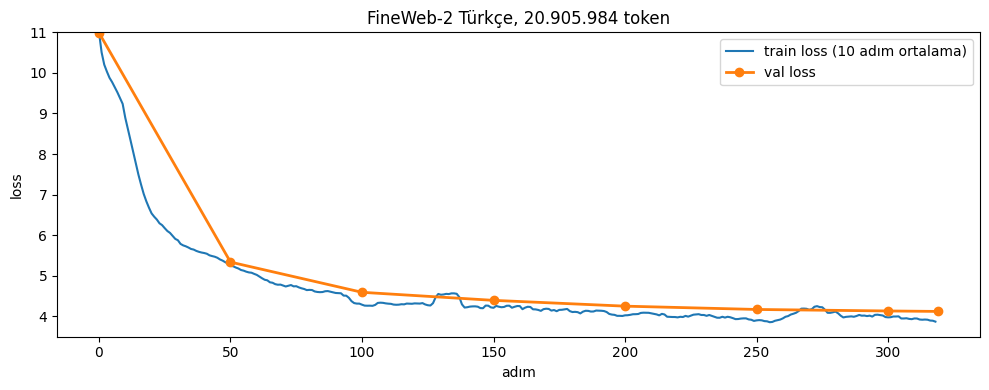

=== "Türkiye'nin en güzel şehirlerinden biri" ===


  "Türkiye'nin en güzel şehirlerinden biri değu döyle açarında, mem. Eğlendi zor ameliklerde kın en çiftlik yaşlı olu türlara başi ve"
  "Türkiye'nin en güzel şehirlerinden biri sadeceğinde alan mündaki mülkezi geçler ve insanılı.\nİNıtaya sonunda önınında alı olması"
  "Türkiye'nin en güzel şehirlerinden birişıkça getir.\n-ık-Dost yere dostaği bir sözüntüzler yan da güstünüp onunanılendız"

=== 'Bugün okulda öğretmenimiz bize' ===


  'Bugün okulda öğretmenimiz bize uzellik kolabert tüşın fiz çe alıyice ön kullanıyla öz daklı ocın ihtiyaçekten'
  'Bugün okulda öğretmenimiz bize için çı sülemesine, şönetmeniniz işletişlayınımışmaklarıcışmeyor. İŞimiz'
  'Bugün okulda öğretmenimiz bize öldürki aşında yer bönderme ile bir bölüşüküvenini döndeki ile çekkürkişe göre kabul et'

=== 'Yapay zeka' ===


  'Yapay zekayece kol açen sekanıkı ayi aksında seygamberseklarığınıylağim.\nHük dal.\nGazına geli'
  'Yapay zeka için yatıp bu de bencekadaşin birecekla uygun bir şartında sösterme saldın.\nİMÜRLIRLER�'
  'Yapay zekaye kurun olamaz mak tavu bu sorunuz girmi içinde bulunununabilir? Bu şok dü yörelerinden de göstermişim'



In [31]:
tr_adim, tr_val_deger = zip(*tr_log["val"])
fig, eksen = plt.subplots(figsize=(10, 4))
eksen.plot(tr_log["train"]["adim"], tr_log["train"]["loss"].rolling(10, min_periods=1).mean(), linewidth=1.5, label="train loss (10 adım ortalama)")
eksen.plot(tr_adim, tr_val_deger, marker="o", linewidth=2, label="val loss")
eksen.set_ylim(top=min(11, max(tr_val_deger) + 0.3))
eksen.set_xlabel("adım")
eksen.set_ylabel("loss")
eksen.set_title(f"FineWeb-2 Türkçe, {nokta(TR_MAX_ADIM * TOPLAM_BATCH)} token")
eksen.legend()
plt.tight_layout()
plt.show()

for baslangic in ["Türkiye'nin en güzel şehirlerinden biri", "Bugün okulda öğretmenimiz bize", "Yapay zeka"]:
    print(f"=== {baslangic!r} ===")
    for metin in ornek_uret(tr_model, baslangic, adet=3, uzunluk=48):
        print(f"  {metin!r}")
    print()

Türkçe modeli HellaSwag'le ölçemem ama aynı fikirleri Türkçe veriyle kullanabilirim. İlk ve en kolay ölçü, modelin hiç görmediği Türkçe metindeki loss. Aşağıda üç modeli aynı Türkçe doğrulama token'larında ölçtüm: Türkçe modelim, İngilizce eğittiğim modelim ve OpenAI GPT-2. Üçü de aynı tokenizer'ı kullandığı için loss'lar doğrudan karşılaştırılabilir. Aynı şeyi İngilizce doğrulama shard'ında da yaptım.

In [32]:
model = model.to(device)
gpt2_model = gpt2_model.to(device)
satirlar = []
for ad, m in [("Türkçe modelim (FineWeb-2 tr)", tr_model), ("İngilizce modelim (FineWeb-Edu)", model), ("OpenAI GPT-2 (124M)", gpt2_model)]:
    satirlar.append((ad, f"{val_loss_olc(m, tr_val_loader):.4f}", f"{val_loss_olc(m, val_loader):.4f}"))
display(pd.DataFrame(satirlar, columns=["Model", "Türkçe val loss", "İngilizce val loss"]).style.hide(axis="index"))

Model,Türkçe val loss,İngilizce val loss
Türkçe modelim (FineWeb-2 tr),4.1221,8.9605
İngilizce modelim (FineWeb-Edu),7.1789,4.8142
OpenAI GPT-2 (124M),4.5585,3.2641


**Cevap: Türkçe model ne üretiyor?**

FineWeb-2'den 18.345 Türkçe belge ve 30M eğitim token'ı aldım. Model 15 dakikada 319 adım ve **20.9M token** gördü (verinin %70'i), hız ~25 bin token/sn. Val loss 10.99'dan **4.12**'ye indi.

Üretilen metin Türkçeye **benziyor** ama anlamlı değil. Ekler yerinde ve doğru kullanılıyor (`-lerinin`, `-ıyla`, `-ması`, `-mişim`), bazı gerçek kelimeler ve ifadeler çıkıyor ("insanı", "kabul et", "bu sorunuz", "uygun bir", "çiftlik"). Ama kelimelerin çoğu uydurma ("döyle", "mülkezi", "sösterme") ve cümle kurulmuyor. İngilizce modelin 250. adımdaki hâline benziyor.

Bence sebep Hafta 10'da gördüğüm tokenizer sorunu. Türkçe GPT-2 tokenizer'ında byte başına 2.01 token, İngilizcede 4.64. Aynı 20.9M token Türkçede 2.3 kat daha az metin demek. Üstelik kelimeler 3–5 parçaya bölündüğü için model önce parçalardan kelime kurmayı öğrenmek zorunda. Uydurma kelimeler de buradan geliyor: model gerçek parçaları yanlış sırayla yan yana koyuyor.

Yine de 15 dakikalık modelim Türkçe doğrulama metninde **OpenAI GPT-2'den daha iyi loss alıyor: 4.12'ye 4.56.** GPT-2'nin İngilizcedeki loss'u 3.26, yani Türkçede çok zayıf. Hafta 10'da da GPT-2'nin Türkçe çıktısının kötü olduğunu görmüştüm. İngilizce modelim Türkçede 7.18, Türkçe modelim İngilizcede 8.96 alıyor: iki model de sadece eğitildiği dili biliyor.

**Cevap: HellaSwag İngilizce olduğu için Türkçe modeli nasıl ölçerdim?**

1. **Görülmemiş Türkçe metinde loss.** Yukarıda yaptığım bu. Aynı tokenizer'ı kullanan modelleri doğrudan karşılaştırabilirim. Farklı tokenizer'larda Hafta 11 Görev 4'teki gibi byte başına bit (bpb) kullanırım. En kolay ve en ucuz ölçü bu.
2. **HellaSwag'in yöntemini Türkçe bir veri setinde kullanmak.** `hellaswag_olc` dile bağlı değil: bağlamı ve seçenekleri verip devam kısmının ortalama loss'una bakıyor. Bunu Türkçe çoktan seçmeli bir veriye uygulayabilirim. XCOPA'nın Türkçe kısmında sebep-sonuç soruları var (2 seçenek, rastgele %50). Belebele'nin Türkçe kısmı okuma anlama soruları (4 seçenek), XNLI'nin Türkçe kısmı da kullanılabilir. HellaSwag'in Türkçeye çevrilmiş bir hali de olabilir, ama çeviri hataları ve İngilizceye özgü sahneler (Amerikan sporları, WikiHow tarifleri) ölçümü bozar.
3. **Türkçeye özgü küçük testler.** Ünlü uyumu ve ek doğruluğu için cümle çiftleri hazırlarım ("evlerde oturuyoruz" ile "evlarda oturuyoruz", "kitabı okudum" ile "kitabi okudum") ve modelin doğru olana daha düşük loss verip vermediğine bakarım. Bu, HellaSwag'den çok daha basit, ama 15 dakikalık bir modelin ne öğrendiğini görmek için uygun.
4. **İnsan değerlendirmesi.** Üretilen metinleri birkaç kişiye okutup akıcılık ve anlam için puanlatmak. En pahalısı ama sonunda asıl önemli olan bu.